# LCF / RAP 鲁棒性程序与对应图

每个代码单元均保留原程序内容；执行结果和图片已嵌入单元下方。

## 1. `2比特V20MHzRAPδΩδΔ.txt`

  行 21/21 完成


RAP 中心点 F0 = 0.999453    +/-5% 网格: 中心 F=0.999453, 最小 F=0.960776, 最大 F=0.999453


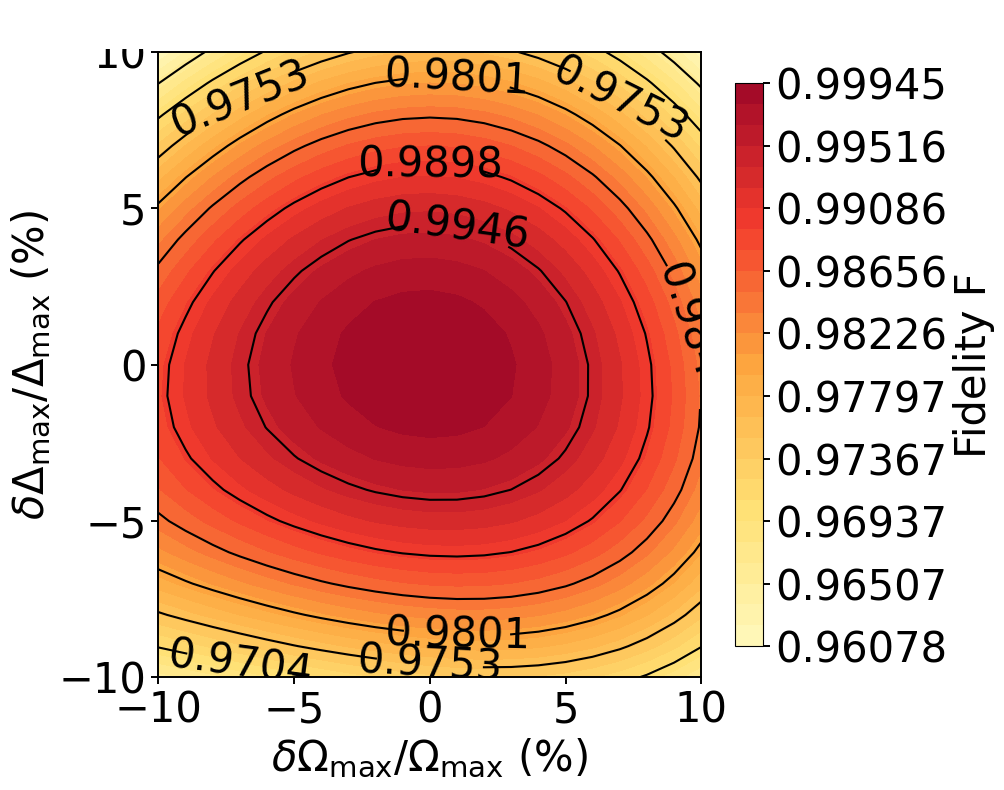

图已保存: paper_RAP.png


In [1]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['2比特V20MHzRAPδΩδΔ.txt']
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0        # Ω10 = 2π×100 MHz
gamma_r = 1.0/540.0            # 里德堡态总耗散率 (Cs |107P3/2>), 540 µs 寿命

# 无量纲耗散率
Gamma = gamma_r/Omega10
Gamma_spont = Gamma / 16.0     # 每通道自发辐射率 (r→0, r→1)
Gamma_deph  = 7.0 * Gamma / 8.0  # 退相位率

# ==================== 9 维 Hilbert 空间 ====================
st = [''.join(p) for p in product('01r', repeat=2)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

Cc = np.zeros((d, d))                        # 耦合 Σ_a (|r><1|+h.c.)/2
for s, i in idx.items():
    for a in range(2):
        if s[a] == '1':
            Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r':
            Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)                            # 失谐项 (|rr⟩ 计 2Δ)
Err = np.zeros((d, d)); Err[idx['rr'], idx['rr']] = 1.0
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])             # πg 置换 (0↔1)

psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)

# ==================== Lindblad 跳跃算符（完整形式） ====================
L_ops = []
for a in range(2):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
for a in range(2):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))
LdL_list = [L.conj().T @ L for L in L_ops]


# ==================== 脉冲（归一化包络，峰值=1 / ±1） ====================
def make_pulse_lcf(tau_tot, sR, sD, PF):
    """无能级交叉脉冲（高斯导数型），框架自带形式。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        tau_pi = PF*tau_tot
        tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
        xR = (tau - tm)/sR
        xD = (tau - tm)/sD
        Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
        De = np.e*xD**2*np.exp(-xD**2)
        return Om, De
    return pulse

def make_pulse_rap(tau_tot, tau_R, tau_D):
    """两段绝热通道 RAP 脉冲（fig2ef_rap.py 形式，τR,τD 独立）。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        a = np.exp(-(tau_tot/(4*tau_R))**4)
        k = np.where(tau <= tau_tot/2, 1.0, 2.0)
        tk = (2*k - 1)*tau_tot/4.0
        sign = np.where(k == 1.0, 1.0, -1.0)
        Om = (np.exp(-((tau - tk)/tau_R)**4) - a)/(1.0 - a)
        De = sign*np.sin(np.pi*(tau - tk)/tau_D)
        return Om, De
    return pulse


# ==================== 含耗散保真度（RK4，相对误差 dO/dD %） ====================
def make_fidelity(tau_tot, OM1max, DE1max, V0, PF, pulse_fn, dt=0.05, diss=True):
    def fidelity(dO=0.0, dD=0.0):
        dO = np.atleast_1d(np.asarray(dO, float))
        dD = np.atleast_1d(np.asarray(dD, float))
        OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)   # 有效峰值
        DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]

        def deriv(rho, Om, De):
            H = De[:, None, None]*DrG + Om[:, None, None]*CcG + ErrG
            dr = -1j*(H@rho - rho@H)
            if diss:
                for L, LdL in zip(L_ops, LdL_list):
                    Lc = L.conj().T
                    dr += (L[None] @ rho @ Lc[None]
                           - 0.5*(LdL[None] @ rho + rho @ LdL[None]))
            return dr

        N = int(round(tau_tot/dt))
        n_pi = int(round(PF*N))                 # 中点施加 πg
        rho = np.zeros((dO.size, d, d), complex)
        rho[:, idx['11'], idx['11']] = 1.0
        for n in range(N):
            t0 = n*dt
            Om0, De0 = pulse_fn(t0)
            Omh, Deh = pulse_fn(t0+dt/2)
            Om1, De1 = pulse_fn(t0+dt)
            k1 = deriv(rho, Om0*OmM, De0*DeM)
            k2 = deriv(rho + 0.5*dt*k1, Omh*OmM, Deh*DeM)
            k3 = deriv(rho + 0.5*dt*k2, Omh*OmM, Deh*DeM)
            k4 = deriv(rho + dt*k3, Om1*OmM, De1*DeM)
            rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
            if n == n_pi - 1:
                rho = rho[:, g_perm[:, None], g_perm[None, :]]
        return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))
    return fidelity


# ==================== RAP 候选 A 最优参数 ====================
# 标称: (τ, τR, τD, Δ0, V0, Ωmax) = (393.1252,470.1845,392.0985,0.0904,0.20,0.0334)
# 若想对齐桌面 bell_omega05_lcf_rap.py 的“共同 Ωmax=5MHz”基准，把下面 OM1max 改成 0.05 即可。
tau_tot = 393.1252
tau_R, tau_D = 470.1845, 392.0985
PF      = 0.5
DE1max  = 0.0904
V0      = 0.20
OM1max  = 0.0334            
fid = make_fidelity(tau_tot=tau_tot, OM1max=OM1max, DE1max=DE1max,
                    V0=V0, PF=PF,
                    pulse_fn=make_pulse_rap(tau_tot, tau_R, tau_D))


# ==================== ±10% 鲁棒性扫描 (21×21)，以最优点为 (0,0) ====================
offsets = np.linspace(-10, 10, 11)

grid = np.zeros((len(offsets), len(offsets)))
for i, dD in enumerate(offsets):
    grid[i, :] = fid(dO=offsets, dD=dD)    # 行: δΔ0, 列: δΩmax
    print(f"  行 {i+1}/{len(offsets)} 完成", end='\r')
print()
F0 = fid()[0]
print(f"RAP 中心点 F0 = {F0:.6f}    "
      f"+/-5% 网格: 中心 F={grid[len(offsets)//2, len(offsets)//2]:.6f}, "
      f"最小 F={grid.min():.6f}, 最大 F={grid.max():.6f}")


# ==================== 画鲁棒性等高线图（论文形式） ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),   # 淡黄（低值）
    (1.000, 0.878, 0.451),   # 黄
    (0.992, 0.651, 0.247),   # 橙
    (0.953, 0.231, 0.176),   # 红橙
    (0.624, 0.031, 0.157),   # 深红（高值）
])
FS_LAB, FS_TCK = 30, 30
N_LINE = 9   # 等高线根数（均匀分布在自身数据范围内）

f_min = float(grid.min()); f_max = float(grid.max())
if np.isclose(f_min, f_max):
    pad = max(abs(f_min)*1e-6, 1e-9)
    f_min, f_max = f_min - pad, f_max + pad
fill_levels = np.linspace(f_min, f_max, 28)
line_levels = np.linspace(f_min, f_max, N_LINE)

fig, ax = plt.subplots(figsize=(10, 8))
cf = ax.contourf(offsets, offsets, grid, levels=fill_levels, cmap=cmap_ref)
cs = ax.contour(offsets, offsets, grid, levels=line_levels,
                colors='black', linewidths=1.5)
ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black', inline_spacing=3)
F0c = grid[len(offsets)//2, len(offsets)//2]
ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
ax.set_ylabel(r'$\delta\Delta_{\max}/\Delta_{\max}$ (%)', fontsize=FS_LAB)
ax.set_xticks([-10, -5, 0, 5, 10])
ax.set_yticks([-10, -5, 0, 5, 10])
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)
cbar = fig.colorbar(cf, ax=ax, shrink=0.9)
cbar.set_label('Fidelity F', fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
plt.tight_layout()
plt.savefig('paper_RAP.png', dpi=200)
display(fig)
plt.close(fig)
print("图已保存: paper_RAP.png")


## 2. `2比特V20δLFC鲁棒性.txt`

  行 11/11 完成


LCF 中心点 F0 = 0.998795    +/-5% 网格: 中心 F=0.998795, 最小 F=0.975444, 最大 F=0.998795


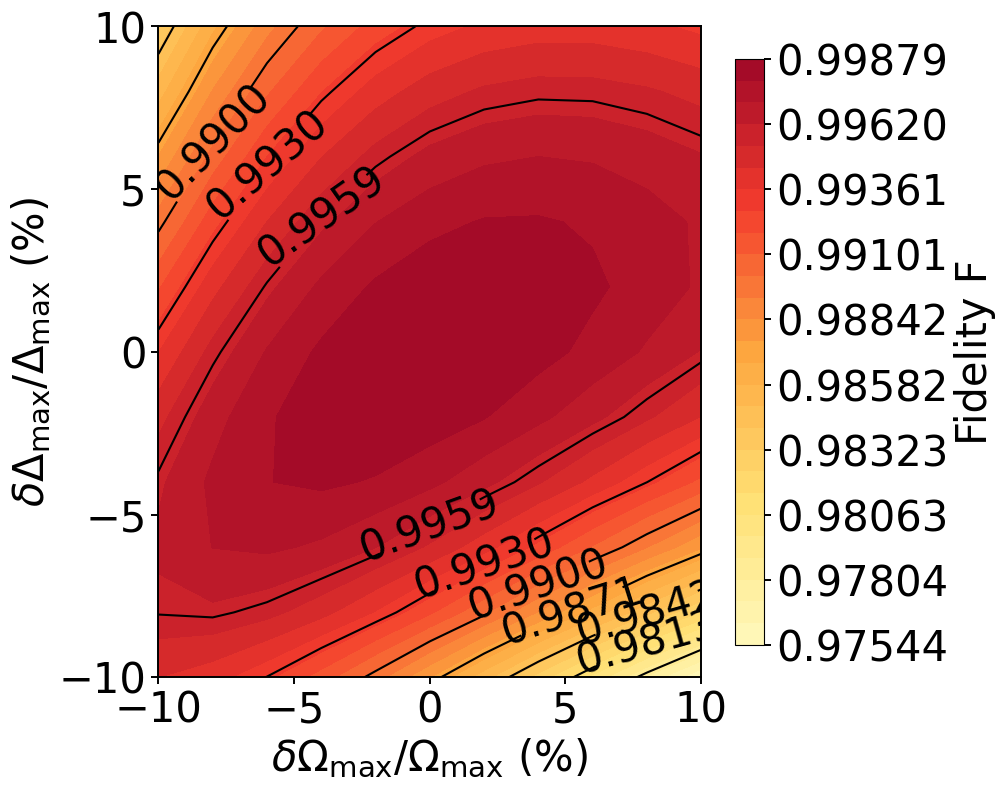

图已保存: paper_LCF.png


In [2]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['2比特V20δLFC鲁棒性.txt']
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma / 16.0
Gamma_deph  = 7.0 * Gamma / 8.0

# ==================== 9 维 Hilbert 空间 ====================
st = [''.join(p) for p in product('01r', repeat=2)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
Cc = np.zeros((d, d))
for s, i in idx.items():
    for a in range(2):
        if s[a] == '1': Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r': Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)
Err = np.zeros((d, d)); Err[idx['rr'], idx['rr']] = 1.0
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)

# ==================== Lindblad 跳跃算符（完整形式） ====================
L_ops = []
for a in range(2):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
for a in range(2):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))
LdL_list = [L.conj().T @ L for L in L_ops]

# ==================== 脉冲（归一化包络，峰值=1 / ±1） ====================
def make_pulse_lcf(tau_tot, sR, sD, PF):
    """无能级交叉脉冲（高斯导数型），框架自带形式。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        tau_pi = PF*tau_tot
        tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
        xR = (tau - tm)/sR
        xD = (tau - tm)/sD
        Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
        De = np.e*xD**2*np.exp(-xD**2)
        return Om, De
    return pulse

def make_pulse_rap(tau_tot, tau_R, tau_D):
    """两段绝热通道 RAP 脉冲（fig2ef_rap.py 形式，τR,τD 独立）。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        a = np.exp(-(tau_tot/(4*tau_R))**4)
        k = np.where(tau <= tau_tot/2, 1.0, 2.0)
        tk = (2*k - 1)*tau_tot/4.0
        sign = np.where(k == 1.0, 1.0, -1.0)
        Om = (np.exp(-((tau - tk)/tau_R)**4) - a)/(1.0 - a)
        De = sign*np.sin(np.pi*(tau - tk)/tau_D)
        return Om, De
    return pulse

# ==================== 含耗散保真度（RK4，相对误差 dO/dD %） ====================
def make_fidelity(tau_tot, OM1max, DE1max, V0, PF, pulse_fn, dt=0.05, diss=True):
    def fidelity(dO=0.0, dD=0.0):
        dO = np.atleast_1d(np.asarray(dO, float))
        dD = np.atleast_1d(np.asarray(dD, float))
        OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)
        DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]
        def deriv(rho, Om, De):
            H = De[:, None, None]*DrG + Om[:, None, None]*CcG + ErrG
            dr = -1j*(H@rho - rho@H)
            if diss:
                for L, LdL in zip(L_ops, LdL_list):
                    Lc = L.conj().T
                    dr += (L[None] @ rho @ Lc[None]
                           - 0.5*(LdL[None] @ rho + rho @ LdL[None]))
            return dr
        N = int(round(tau_tot/dt))
        n_pi = int(round(PF*N))
        rho = np.zeros((dO.size, d, d), complex)
        rho[:, idx['11'], idx['11']] = 1.0
        for n in range(N):
            t0 = n*dt
            Om0, De0 = pulse_fn(t0)
            Omh, Deh = pulse_fn(t0+dt/2)
            Om1, De1 = pulse_fn(t0+dt)
            k1 = deriv(rho, Om0*OmM, De0*DeM)
            k2 = deriv(rho + 0.5*dt*k1, Omh*OmM, Deh*DeM)
            k3 = deriv(rho + 0.5*dt*k2, Omh*OmM, Deh*DeM)
            k4 = deriv(rho + dt*k3, Om1*OmM, De1*DeM)
            rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
            if n == n_pi - 1:
                rho = rho[:, g_perm[:, None], g_perm[None, :]]
        return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))
    return fidelity

# ==================== LCF 最优参数 ====================
# 标称: (τ, τR, τD, Δ0, V0, Ωmax) = (757.549,105.214,284.271,0.095775,0.20,0.048661)
tau_tot = 757.549
sR, sD  = 105.214, 284.271
PF      = 0.5
DE1max  = 0.095775
V0      = 0.20
OM1max  = 0.048661
fid = make_fidelity(tau_tot=tau_tot, OM1max=OM1max, DE1max=DE1max,
                    V0=V0, PF=PF,
                    pulse_fn=make_pulse_lcf(tau_tot, sR, sD, PF))

# ==================== ±10% 鲁棒性扫描 (21×21)，以最优点为 (0,0) ====================
offsets = np.linspace(-10, 10, 11)
grid = np.zeros((len(offsets), len(offsets)))
for i, dD in enumerate(offsets):
    grid[i, :] = fid(dO=offsets, dD=dD)
    print(f"  行 {i+1}/{len(offsets)} 完成", end='\r')
print()
F0 = fid()[0]
print(f"LCF 中心点 F0 = {F0:.6f}    "
      f"+/-5% 网格: 中心 F={grid[len(offsets)//2, len(offsets)//2]:.6f}, "
      f"最小 F={grid.min():.6f}, 最大 F={grid.max():.6f}")

# ==================== 画鲁棒性等高线图（论文形式） ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),
    (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247),
    (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
FS_LAB, FS_TCK = 30, 30
N_LINE = 9
f_min = float(grid.min()); f_max = float(grid.max())
if np.isclose(f_min, f_max):
    pad = max(abs(f_min)*1e-6, 1e-9)
    f_min, f_max = f_min - pad, f_max + pad
fill_levels = np.linspace(f_min, f_max, 28)
line_levels = np.linspace(f_min, f_max, N_LINE)
fig, ax = plt.subplots(figsize=(10, 8))
cf = ax.contourf(offsets, offsets, grid, levels=fill_levels, cmap=cmap_ref)
cs = ax.contour(offsets, offsets, grid, levels=line_levels,
                colors='black', linewidths=1.5)
ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black', inline_spacing=3)
F0c = grid[len(offsets)//2, len(offsets)//2]
ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
ax.set_ylabel(r'$\delta\Delta_{\max}/\Delta_{\max}$ (%)', fontsize=FS_LAB)
ax.set_xticks([-10, -5, 0, 5, 10])
ax.set_yticks([-10, -5, 0, 5, 10])
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
cbar = fig.colorbar(cf, ax=ax, shrink=0.9)
cbar.set_label('Fidelity F', fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
plt.tight_layout()
plt.savefig('paper_LCF.png', dpi=200)
display(fig)
plt.close(fig)
print("图已保存: paper_LCF.png")



## 3. `panel1_LCF_dv_formatted.py`

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel1_LCF_dv.png C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel1_LCF_dv.pdf


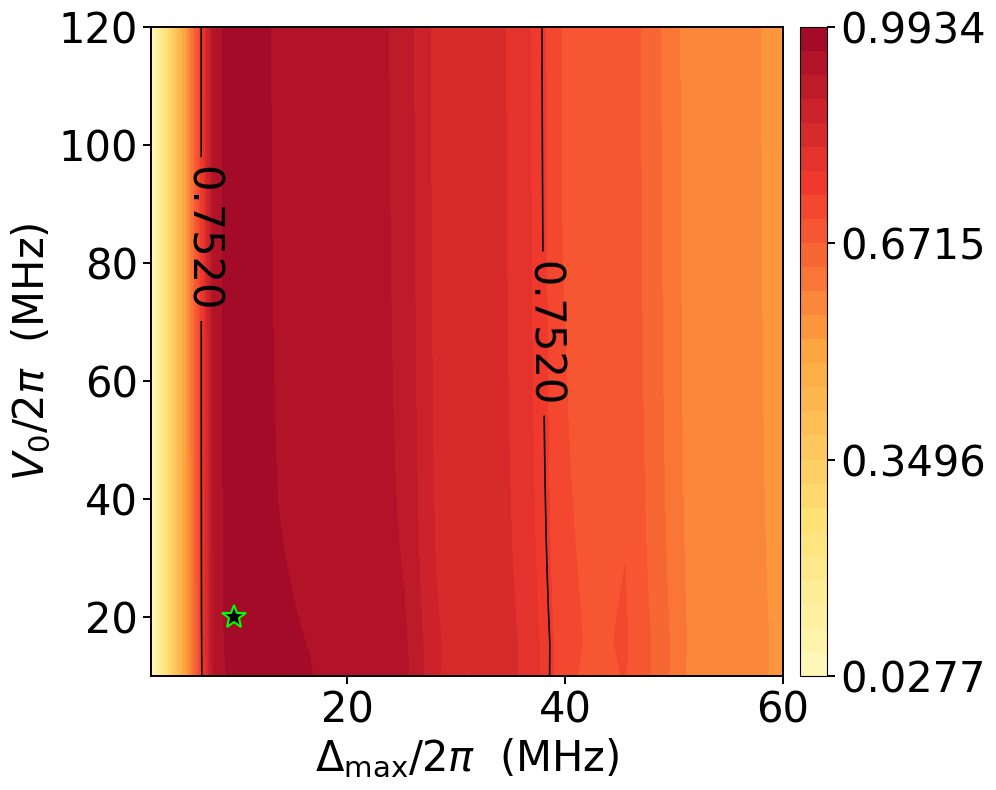

In [3]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['panel1_LCF_dv_formatted.py']
# -*- coding: utf-8 -*-
import numpy as np
from itertools import product
from pathlib import Path
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 字体和输出方式与“2比特ΔΩ.txt”保持一致：使用 Matplotlib 默认字体，
# 各类文字在绘图处显式设为 30 pt，不进行 tight bbox 自动裁剪。

# ===== 公共参数 =====
Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph = 7*Gamma/8
N_step = 300

# ===== 2 原子 Hilbert 空间 (9 维) =====
N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Ei_factor = n_r*(n_r-1)/2
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')] for s in st])
spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)
rr = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

# ===== LCF 脉冲 (固定最优 τ=757.549 ns) =====
Omega_max_L = 0.048661
t_gate_L = 757.549
D0_L = 0.095775
sD_L = 284.271
sR_L = 105.214
pf_L = 0.500
t_L = (np.arange(N_step)+0.5)*t_gate_L/N_step
t_pi_L = pf_L*t_gate_L
tm_L = np.where(t_L < t_pi_L, t_pi_L/2, t_pi_L + (t_gate_L - t_pi_L)/2)
xR_L = (t_L-tm_L)/sR_L; xD_L = (t_L-tm_L)/sD_L
base_Om_L = -Omega_max_L*np.sqrt(2*np.e)*xR_L*np.exp(-xR_L**2)
base_De_L = D0_L*np.e*xD_L**2*np.exp(-xD_L**2)
dt_L = t_gate_L/N_step
n_pi_L = int(round(pf_L*N_step))

# ===== RAP-A 脉冲 (固定最优 τ=393.125 ns) =====
Omega_max_R = 0.0334
t_gate_R = 393.1252
D0_R = 0.0904
sD_R = 392.0985
sR_R = 470.1845
t_R = (np.arange(N_step)+0.5)*t_gate_R/N_step
tau_R_R = sR_R
tau_D_R = sD_R
_a_R = np.exp(-(t_gate_R/(4*tau_R_R))**4)
k_R = np.where(t_R <= t_gate_R/2, 1.0, 2.0)
tk_R = (2.0*k_R - 1.0)*t_gate_R/4.0
sign_R = np.where(k_R == 1.0, 1.0, -1.0)
base_Om_R = Omega_max_R*(np.exp(-((t_R-tk_R)/tau_R_R)**4) - _a_R)/(1.0 - _a_R)
base_De_R = D0_R*sign_R*np.sin(np.pi*(t_R-tk_R)/tau_D_R)
dt_R = t_gate_R/N_step
n_pi_R = N_step//2

def simulate_batch(base_Om, base_De, dt, n_pi, Om, D0, V0):
    B = Om.shape[0]
    drive = base_Om[None, :, None, None] * Om[:, None, None, None] * C[None, None]
    diag_vals = (base_De[None, :, None]*D0[:, None, None]) * n_r[None, None, :] \
                + (V0[:, None, None]*Ei_factor[None, None, :])
    H = drive.copy()
    H[:, :, rr, rr] = diag_vals
    w, v = np.linalg.eigh(H)
    Uh = v * np.exp(-1j*w*dt/2)[:, :, None, :] @ np.swapaxes(v.conj(), -2, -1)
    rho = np.einsum('bi,bj->bij', psi0[None], psi0[None].conj())
    for n in range(N_step):
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        jump = D_deph[None]*rho
        for src, dst in spont:
            jump[:, dst[:, None], dst[None, :]] += Gamma_spont*rho[:, src[:, None], src[None, :]]
        rho = rho + dt*(jump - 0.5*anti[None]*rho)
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        if n == n_pi - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    F = np.real(np.einsum('i,bij,j->b', psiT.conj(), rho, psiT))
    return F

def scan2(scheme, ax1_vals, ax2_vals, fixed):
    if scheme == 'lcf':
        base_Om, base_De, dt, n_pi = base_Om_L, base_De_L, dt_L, n_pi_L
        Om0, D00 = Omega_max_L, D0_L
    else:
        base_Om, base_De, dt, n_pi = base_Om_R, base_De_R, dt_R, n_pi_R
        Om0, D00 = Omega_max_R, D0_R
    N1, N2 = len(ax1_vals), len(ax2_vals)
    A1, A2 = np.meshgrid(ax1_vals, ax2_vals, indexing='ij')
    if fixed[0] == 'dv':
        Om_fix = fixed[1]
        Om = np.full(A1.size, Om_fix/Om0)
        D0 = A1.ravel()/D00
        V0 = A2.ravel()
    else:
        V0_fix = fixed[1]
        Om = A1.ravel()/Om0
        D0 = A2.ravel()/D00
        V0 = np.full(A1.size, V0_fix)
    F = np.empty(A1.size)
    CH = 256
    for s in range(0, A1.size, CH):
        F[s:s+CH] = simulate_batch(base_Om, base_De, dt, n_pi,
                                   Om[s:s+CH], D0[s:s+CH], V0[s:s+CH])
    return F.reshape(N1, N2)

# ===== panel1: LCF (Δ0,V0) @ Ωmax=5 MHz =====
d0g = np.linspace(0.02, 0.60, 21)
v0g = np.linspace(0.10, 1.20, 21)
F = scan2('lcf', d0g, v0g, ('dv', 0.05))
star = (0.095775, 0.20); star_color = "lime"
xlab = r"$\Delta_{\max}/2\pi$  (MHz)"; ylab = r"$V_0/2\pi$  (MHz)"
outdir = Path.cwd()
outdir.mkdir(parents=True, exist_ok=True)
fname = "bell_panel1_LCF_dv"

fig, ax = plt.subplots(figsize=(10, 8))
Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
    (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
cf = ax.contourf(d0g*100, v0g*100, Fp.T,
                 levels=np.linspace(fmin, fmax, 28), cmap=cmap_ref)
# 只保留高值等高线；去掉原来的 0.5129 等高线。
cl = np.linspace(fmin, fmax, 5)[3:4]
cs = ax.contour(d0g*100, v0g*100, Fp.T, levels=cl,
                colors="k", linewidths=1.15)
ax.clabel(cs, fmt="%.4f", fontsize=30, inline=True, inline_spacing=5,
          manual=[(7.0, 84.0), (38.0, 68.0)])
cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                  pad=0.025, fraction=0.055, aspect=24)
cb.ax.tick_params(labelsize=30, width=1.4, length=6)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.plot(star[0]*100, star[1]*100, "*", ms=18, color="k", mec=star_color, mew=1.5)
ax.set_xlabel(xlab, fontsize=30); ax.set_ylabel(ylab, fontsize=30)
ax.tick_params(axis="both", labelsize=30, width=1.4, length=6)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
fig.tight_layout()
fig.savefig(outdir/f"{fname}.png", dpi=200)
fig.savefig(outdir/f"{fname}.pdf")
print("saved", outdir/f"{fname}.png", outdir/f"{fname}.pdf")

display(fig)
plt.close(fig)


## 4. `panel2_RAP_dv_formatted.py`

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel2_RAP_dv.png C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel2_RAP_dv.pdf


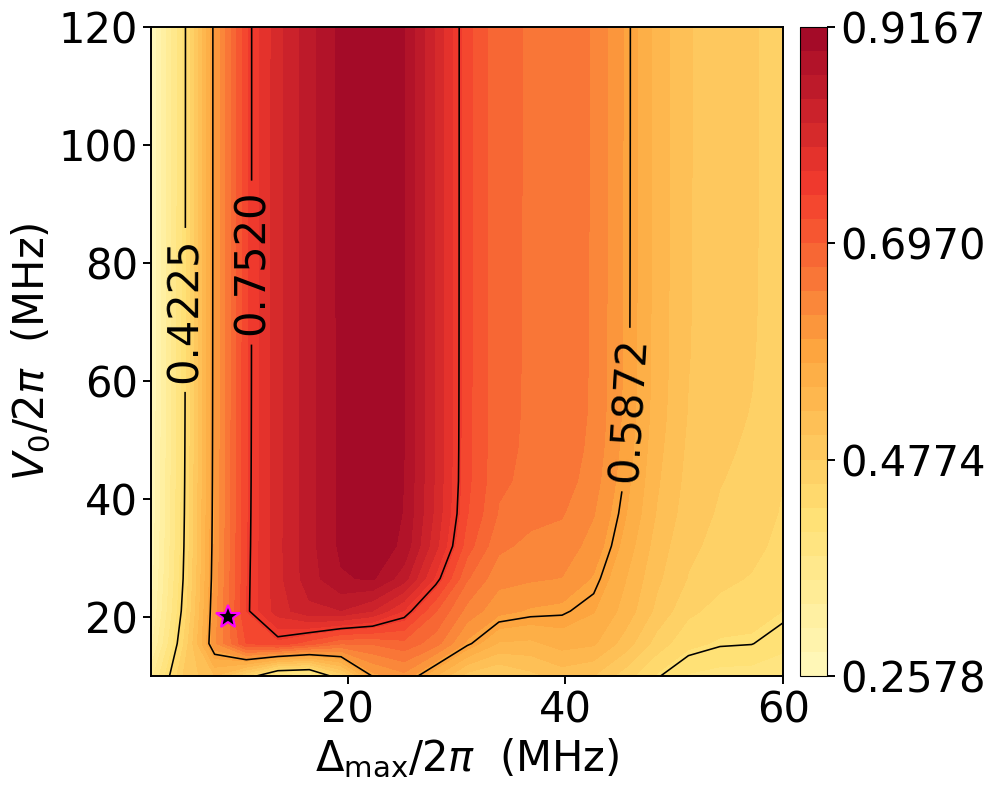

In [4]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['panel2_RAP_dv_formatted.py']
# -*- coding: utf-8 -*-
import numpy as np
from itertools import product
from pathlib import Path
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 字体和输出方式与“2比特ΔΩ.txt”保持一致。

Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph = 7*Gamma/8
N_step = 300

N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Ei_factor = n_r*(n_r-1)/2
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')] for s in st])
spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)
rr = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

Omega_max_L = 0.048661
t_gate_L = 757.549
D0_L = 0.095775
sD_L = 284.271
sR_L = 105.214
pf_L = 0.500
t_L = (np.arange(N_step)+0.5)*t_gate_L/N_step
t_pi_L = pf_L*t_gate_L
tm_L = np.where(t_L < t_pi_L, t_pi_L/2, t_pi_L + (t_gate_L - t_pi_L)/2)
xR_L = (t_L-tm_L)/sR_L; xD_L = (t_L-tm_L)/sD_L
base_Om_L = -Omega_max_L*np.sqrt(2*np.e)*xR_L*np.exp(-xR_L**2)
base_De_L = D0_L*np.e*xD_L**2*np.exp(-xD_L**2)
dt_L = t_gate_L/N_step
n_pi_L = int(round(pf_L*N_step))

Omega_max_R = 0.0334
t_gate_R = 393.1252
D0_R = 0.0904
sD_R = 392.0985
sR_R = 470.1845
t_R = (np.arange(N_step)+0.5)*t_gate_R/N_step
tau_R_R = sR_R
tau_D_R = sD_R
_a_R = np.exp(-(t_gate_R/(4*tau_R_R))**4)
k_R = np.where(t_R <= t_gate_R/2, 1.0, 2.0)
tk_R = (2.0*k_R - 1.0)*t_gate_R/4.0
sign_R = np.where(k_R == 1.0, 1.0, -1.0)
base_Om_R = Omega_max_R*(np.exp(-((t_R-tk_R)/tau_R_R)**4) - _a_R)/(1.0 - _a_R)
base_De_R = D0_R*sign_R*np.sin(np.pi*(t_R-tk_R)/tau_D_R)
dt_R = t_gate_R/N_step
n_pi_R = N_step//2

def simulate_batch(base_Om, base_De, dt, n_pi, Om, D0, V0):
    B = Om.shape[0]
    drive = base_Om[None, :, None, None] * Om[:, None, None, None] * C[None, None]
    diag_vals = (base_De[None, :, None]*D0[:, None, None]) * n_r[None, None, :] \
                + (V0[:, None, None]*Ei_factor[None, None, :])
    H = drive.copy()
    H[:, :, rr, rr] = diag_vals
    w, v = np.linalg.eigh(H)
    Uh = v * np.exp(-1j*w*dt/2)[:, :, None, :] @ np.swapaxes(v.conj(), -2, -1)
    rho = np.einsum('bi,bj->bij', psi0[None], psi0[None].conj())
    for n in range(N_step):
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        jump = D_deph[None]*rho
        for src, dst in spont:
            jump[:, dst[:, None], dst[None, :]] += Gamma_spont*rho[:, src[:, None], src[None, :]]
        rho = rho + dt*(jump - 0.5*anti[None]*rho)
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        if n == n_pi - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    F = np.real(np.einsum('i,bij,j->b', psiT.conj(), rho, psiT))
    return F

def scan2(scheme, ax1_vals, ax2_vals, fixed):
    if scheme == 'lcf':
        base_Om, base_De, dt, n_pi = base_Om_L, base_De_L, dt_L, n_pi_L
        Om0, D00 = Omega_max_L, D0_L
    else:
        base_Om, base_De, dt, n_pi = base_Om_R, base_De_R, dt_R, n_pi_R
        Om0, D00 = Omega_max_R, D0_R
    N1, N2 = len(ax1_vals), len(ax2_vals)
    A1, A2 = np.meshgrid(ax1_vals, ax2_vals, indexing='ij')
    if fixed[0] == 'dv':
        Om_fix = fixed[1]
        Om = np.full(A1.size, Om_fix/Om0)
        D0 = A1.ravel()/D00
        V0 = A2.ravel()
    else:
        V0_fix = fixed[1]
        Om = A1.ravel()/Om0
        D0 = A2.ravel()/D00
        V0 = np.full(A1.size, V0_fix)
    F = np.empty(A1.size)
    CH = 256
    for s in range(0, A1.size, CH):
        F[s:s+CH] = simulate_batch(base_Om, base_De, dt, n_pi,
                                   Om[s:s+CH], D0[s:s+CH], V0[s:s+CH])
    return F.reshape(N1, N2)

# ===== panel2: RAP (Δ0,V0) @ Ωmax=5 MHz =====
d0g = np.linspace(0.02, 0.60, 21)
v0g = np.linspace(0.10, 1.20, 21)
F = scan2('rap', d0g, v0g, ('dv', 0.05))
star = (0.0904, 0.20); star_color = "magenta"
xlab = r"$\Delta_{\max}/2\pi$  (MHz)"; ylab = r"$V_0/2\pi$  (MHz)"
outdir = Path.cwd()
outdir.mkdir(parents=True, exist_ok=True)
fname = "bell_panel2_RAP_dv"

fig, ax = plt.subplots(figsize=(10, 8))
Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
    (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
cf = ax.contourf(d0g*100, v0g*100, Fp.T,
                 levels=np.linspace(fmin, fmax, 28), cmap=cmap_ref)
cl = np.linspace(fmin, fmax, 5)[1:-1]
cs = ax.contour(d0g*100, v0g*100, Fp.T, levels=cl,
                colors="k", linewidths=1.15)
ax.clabel(cs, fmt="%.4f", fontsize=30, inline=True, inline_spacing=5,
          manual=[(6.0, 72.0), (18.0, 80.0), (47.0, 55.0)])
cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                  pad=0.025, fraction=0.055, aspect=24)
cb.ax.tick_params(labelsize=30, width=1.4, length=6)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.plot(star[0]*100, star[1]*100, "*", ms=18, color="k", mec=star_color, mew=1.5)
ax.set_xlabel(xlab, fontsize=30); ax.set_ylabel(ylab, fontsize=30)
ax.tick_params(axis="both", labelsize=30, width=1.4, length=6)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
fig.tight_layout()
fig.savefig(outdir/f"{fname}.png", dpi=200)
fig.savefig(outdir/f"{fname}.pdf")
print("saved", outdir/f"{fname}.png", outdir/f"{fname}.pdf")

display(fig)
plt.close(fig)


## 5. `panel3_LCF_wd_formatted.py`

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel3_LCF_wd.png C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel3_LCF_wd.pdf


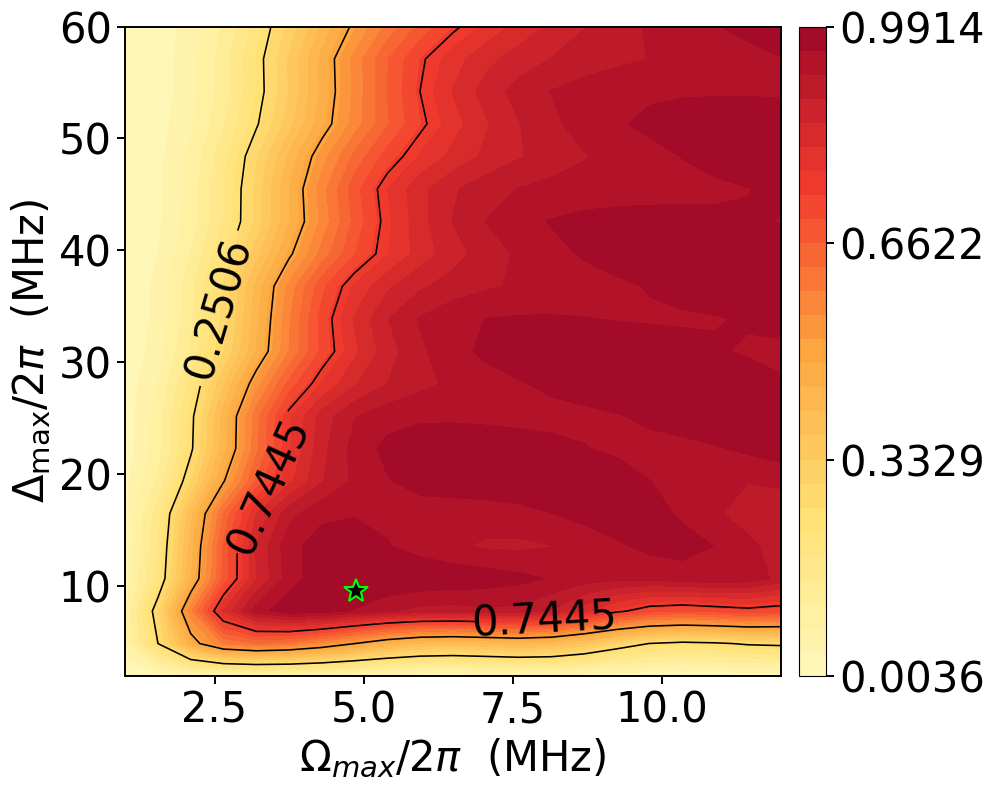

In [5]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['panel3_LCF_wd_formatted.py']
# -*- coding: utf-8 -*-
import numpy as np
from itertools import product
from pathlib import Path
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 字体和输出方式与“2比特ΔΩ.txt”保持一致。

Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph = 7*Gamma/8
N_step = 300

N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Ei_factor = n_r*(n_r-1)/2
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')] for s in st])
spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)
rr = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

Omega_max_L = 0.048661
t_gate_L = 757.549
D0_L = 0.095775
sD_L = 284.271
sR_L = 105.214
pf_L = 0.500
t_L = (np.arange(N_step)+0.5)*t_gate_L/N_step
t_pi_L = pf_L*t_gate_L
tm_L = np.where(t_L < t_pi_L, t_pi_L/2, t_pi_L + (t_gate_L - t_pi_L)/2)
xR_L = (t_L-tm_L)/sR_L; xD_L = (t_L-tm_L)/sD_L
base_Om_L = -Omega_max_L*np.sqrt(2*np.e)*xR_L*np.exp(-xR_L**2)
base_De_L = D0_L*np.e*xD_L**2*np.exp(-xD_L**2)
dt_L = t_gate_L/N_step
n_pi_L = int(round(pf_L*N_step))

Omega_max_R = 0.0334
t_gate_R = 393.1252
D0_R = 0.0904
sD_R = 392.0985
sR_R = 470.1845
t_R = (np.arange(N_step)+0.5)*t_gate_R/N_step
tau_R_R = sR_R
tau_D_R = sD_R
_a_R = np.exp(-(t_gate_R/(4*tau_R_R))**4)
k_R = np.where(t_R <= t_gate_R/2, 1.0, 2.0)
tk_R = (2.0*k_R - 1.0)*t_gate_R/4.0
sign_R = np.where(k_R == 1.0, 1.0, -1.0)
base_Om_R = Omega_max_R*(np.exp(-((t_R-tk_R)/tau_R_R)**4) - _a_R)/(1.0 - _a_R)
base_De_R = D0_R*sign_R*np.sin(np.pi*(t_R-tk_R)/tau_D_R)
dt_R = t_gate_R/N_step
n_pi_R = N_step//2

def simulate_batch(base_Om, base_De, dt, n_pi, Om, D0, V0):
    B = Om.shape[0]
    drive = base_Om[None, :, None, None] * Om[:, None, None, None] * C[None, None]
    diag_vals = (base_De[None, :, None]*D0[:, None, None]) * n_r[None, None, :] \
                + (V0[:, None, None]*Ei_factor[None, None, :])
    H = drive.copy()
    H[:, :, rr, rr] = diag_vals
    w, v = np.linalg.eigh(H)
    Uh = v * np.exp(-1j*w*dt/2)[:, :, None, :] @ np.swapaxes(v.conj(), -2, -1)
    rho = np.einsum('bi,bj->bij', psi0[None], psi0[None].conj())
    for n in range(N_step):
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        jump = D_deph[None]*rho
        for src, dst in spont:
            jump[:, dst[:, None], dst[None, :]] += Gamma_spont*rho[:, src[:, None], src[None, :]]
        rho = rho + dt*(jump - 0.5*anti[None]*rho)
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        if n == n_pi - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    F = np.real(np.einsum('i,bij,j->b', psiT.conj(), rho, psiT))
    return F

def scan2(scheme, ax1_vals, ax2_vals, fixed):
    if scheme == 'lcf':
        base_Om, base_De, dt, n_pi = base_Om_L, base_De_L, dt_L, n_pi_L
        Om0, D00 = Omega_max_L, D0_L
    else:
        base_Om, base_De, dt, n_pi = base_Om_R, base_De_R, dt_R, n_pi_R
        Om0, D00 = Omega_max_R, D0_R
    N1, N2 = len(ax1_vals), len(ax2_vals)
    A1, A2 = np.meshgrid(ax1_vals, ax2_vals, indexing='ij')
    if fixed[0] == 'dv':
        Om_fix = fixed[1]
        Om = np.full(A1.size, Om_fix/Om0)
        D0 = A1.ravel()/D00
        V0 = A2.ravel()
    else:
        V0_fix = fixed[1]
        Om = A1.ravel()/Om0
        D0 = A2.ravel()/D00
        V0 = np.full(A1.size, V0_fix)
    F = np.empty(A1.size)
    CH = 256
    for s in range(0, A1.size, CH):
        F[s:s+CH] = simulate_batch(base_Om, base_De, dt, n_pi,
                                   Om[s:s+CH], D0[s:s+CH], V0[s:s+CH])
    return F.reshape(N1, N2)

# ===== panel3: LCF (Ωmax,Δ0) @ V0=20 MHz =====
wg = np.linspace(0.01, 0.12, 21)
d0b = np.linspace(0.02, 0.60, 21)
F = scan2('lcf', wg, d0b, ('wd', 0.20))
star = (0.048661, 0.095775); star_color = "lime"
xlab = r"$\Omega_{max}/2\pi$  (MHz)"; ylab = r"$\Delta_{\max}/2\pi$  (MHz)"
outdir = Path.cwd()
outdir.mkdir(parents=True, exist_ok=True)
fname = "bell_panel3_LCF_wd"

fig, ax = plt.subplots(figsize=(10, 8))
Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
    (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
cf = ax.contourf(wg*100, d0b*100, Fp.T,
                 levels=np.linspace(fmin, fmax, 28), cmap=cmap_ref)
cl = np.linspace(fmin, fmax, 5)[1:-1]
cs = ax.contour(wg*100, d0b*100, Fp.T, levels=cl,
                colors="k", linewidths=1.15)
ax.clabel(cs, fmt="%.4f", fontsize=30, inline=True, inline_spacing=5,
          manual=[(2.2, 35.0), (3.3, 20.0), (8.0, 13.0)])
cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                  pad=0.025, fraction=0.055, aspect=24)
cb.ax.tick_params(labelsize=30, width=1.4, length=6)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.plot(star[0]*100, star[1]*100, "*", ms=18, color="k", mec=star_color, mew=1.5)
ax.set_xlabel(xlab, fontsize=30); ax.set_ylabel(ylab, fontsize=30)
ax.tick_params(axis="both", labelsize=30, width=1.4, length=6)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
fig.tight_layout()
fig.savefig(outdir/f"{fname}.png", dpi=200)
fig.savefig(outdir/f"{fname}.pdf")
print("saved", outdir/f"{fname}.png", outdir/f"{fname}.pdf")

display(fig)
plt.close(fig)


## 6. `panel4_RAP_wd_formatted.py`

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel4_RAP_wd.png C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\bell_panel4_RAP_wd.pdf


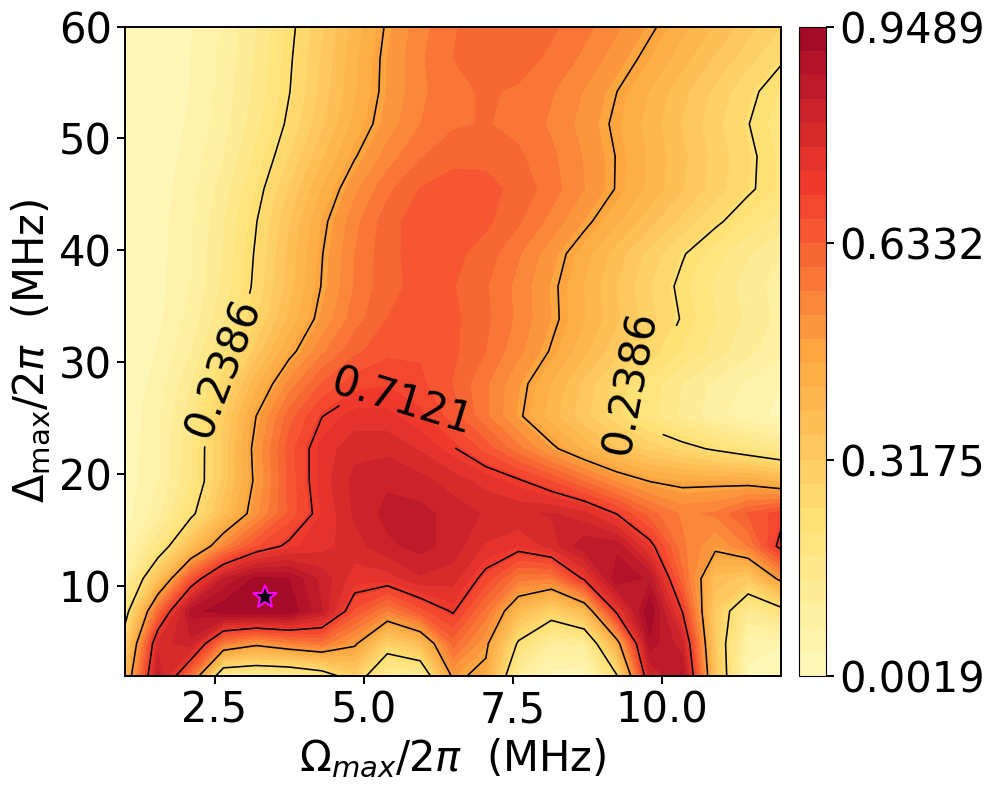

In [6]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['panel4_RAP_wd_formatted.py']
# -*- coding: utf-8 -*-
import numpy as np
from itertools import product
from pathlib import Path
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 字体和输出方式与“2比特ΔΩ.txt”保持一致。

Omega10 = 2*np.pi*100.0
gamma_r = 1.0/540.0
Gamma = gamma_r/Omega10
Gamma_spont = Gamma/16
Gamma_deph = 7*Gamma/8
N_step = 300

N = 2
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)
C = np.zeros((d, d), dtype=complex)
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':   s2 = s[:a]+'r'+s[a+1:]
        elif s[a] == 'r': s2 = s[:a]+'1'+s[a+1:]
        else: continue
        C[idx[s2], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Ei_factor = n_r*(n_r-1)/2
g_perm = np.array([idx[s.replace('0','_').replace('1','0').replace('_','1')] for s in st])
spont = []
for a in range(N):
    for ch in '01':
        src = np.array([i for s, i in idx.items() if s[a] == 'r'])
        dst = np.array([idx[s[:a]+ch+s[a+1:]] for s, i in idx.items() if s[a] == 'r'])
        spont.append((src, dst))
D_deph = np.zeros((d, d))
for a in range(N):
    m = np.array([1.0 if s[a] == 'r' else 0.0 for s in st])
    D_deph += np.outer(m, m)
D_deph *= Gamma_deph
ldl = Gamma * n_r
psi0 = np.zeros(d, complex); psi0[idx['11']] = 1.0
psiT = np.zeros(d, complex)
psiT[idx['01']] = 1/np.sqrt(2); psiT[idx['10']] = 1/np.sqrt(2)
rr = np.arange(d)
anti = ldl[:, None] + ldl[None, :]

Omega_max_L = 0.048661
t_gate_L = 757.549
D0_L = 0.095775
sD_L = 284.271
sR_L = 105.214
pf_L = 0.500
t_L = (np.arange(N_step)+0.5)*t_gate_L/N_step
t_pi_L = pf_L*t_gate_L
tm_L = np.where(t_L < t_pi_L, t_pi_L/2, t_pi_L + (t_gate_L - t_pi_L)/2)
xR_L = (t_L-tm_L)/sR_L; xD_L = (t_L-tm_L)/sD_L
base_Om_L = -Omega_max_L*np.sqrt(2*np.e)*xR_L*np.exp(-xR_L**2)
base_De_L = D0_L*np.e*xD_L**2*np.exp(-xD_L**2)
dt_L = t_gate_L/N_step
n_pi_L = int(round(pf_L*N_step))

Omega_max_R = 0.0334
t_gate_R = 393.1252
D0_R = 0.0904
sD_R = 392.0985
sR_R = 470.1845
t_R = (np.arange(N_step)+0.5)*t_gate_R/N_step
tau_R_R = sR_R
tau_D_R = sD_R
_a_R = np.exp(-(t_gate_R/(4*tau_R_R))**4)
k_R = np.where(t_R <= t_gate_R/2, 1.0, 2.0)
tk_R = (2.0*k_R - 1.0)*t_gate_R/4.0
sign_R = np.where(k_R == 1.0, 1.0, -1.0)
base_Om_R = Omega_max_R*(np.exp(-((t_R-tk_R)/tau_R_R)**4) - _a_R)/(1.0 - _a_R)
base_De_R = D0_R*sign_R*np.sin(np.pi*(t_R-tk_R)/tau_D_R)
dt_R = t_gate_R/N_step
n_pi_R = N_step//2

def simulate_batch(base_Om, base_De, dt, n_pi, Om, D0, V0):
    B = Om.shape[0]
    drive = base_Om[None, :, None, None] * Om[:, None, None, None] * C[None, None]
    diag_vals = (base_De[None, :, None]*D0[:, None, None]) * n_r[None, None, :] \
                + (V0[:, None, None]*Ei_factor[None, None, :])
    H = drive.copy()
    H[:, :, rr, rr] = diag_vals
    w, v = np.linalg.eigh(H)
    Uh = v * np.exp(-1j*w*dt/2)[:, :, None, :] @ np.swapaxes(v.conj(), -2, -1)
    rho = np.einsum('bi,bj->bij', psi0[None], psi0[None].conj())
    for n in range(N_step):
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        jump = D_deph[None]*rho
        for src, dst in spont:
            jump[:, dst[:, None], dst[None, :]] += Gamma_spont*rho[:, src[:, None], src[None, :]]
        rho = rho + dt*(jump - 0.5*anti[None]*rho)
        tmp = np.einsum('bik,bjk->bij', rho, Uh[:, n].conj())
        rho = np.einsum('bik,bkj->bij', Uh[:, n], tmp)
        if n == n_pi - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]
    F = np.real(np.einsum('i,bij,j->b', psiT.conj(), rho, psiT))
    return F

def scan2(scheme, ax1_vals, ax2_vals, fixed):
    if scheme == 'lcf':
        base_Om, base_De, dt, n_pi = base_Om_L, base_De_L, dt_L, n_pi_L
        Om0, D00 = Omega_max_L, D0_L
    else:
        base_Om, base_De, dt, n_pi = base_Om_R, base_De_R, dt_R, n_pi_R
        Om0, D00 = Omega_max_R, D0_R
    N1, N2 = len(ax1_vals), len(ax2_vals)
    A1, A2 = np.meshgrid(ax1_vals, ax2_vals, indexing='ij')
    if fixed[0] == 'dv':
        Om_fix = fixed[1]
        Om = np.full(A1.size, Om_fix/Om0)
        D0 = A1.ravel()/D00
        V0 = A2.ravel()
    else:
        V0_fix = fixed[1]
        Om = A1.ravel()/Om0
        D0 = A2.ravel()/D00
        V0 = np.full(A1.size, V0_fix)
    F = np.empty(A1.size)
    CH = 256
    for s in range(0, A1.size, CH):
        F[s:s+CH] = simulate_batch(base_Om, base_De, dt, n_pi,
                                   Om[s:s+CH], D0[s:s+CH], V0[s:s+CH])
    return F.reshape(N1, N2)

# ===== panel4: RAP (Ωmax,Δ0) @ V0=20 MHz =====
wg = np.linspace(0.01, 0.12, 21)
d0b = np.linspace(0.02, 0.60, 21)
F = scan2('rap', wg, d0b, ('wd', 0.20))
star = (0.0334, 0.0904); star_color = "magenta"
xlab = r"$\Omega_{max}/2\pi$  (MHz)"; ylab = r"$\Delta_{\max}/2\pi$  (MHz)"
outdir = Path.cwd()
outdir.mkdir(parents=True, exist_ok=True)
fname = "bell_panel4_RAP_wd"

fig, ax = plt.subplots(figsize=(10, 8))
Fp = np.where(np.isfinite(F), np.minimum(F, 1.0), np.nan)
fmin, fmax = np.nanmin(Fp), np.nanmax(Fp)
cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
    (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
    (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
    (0.624, 0.031, 0.157),
])
cf = ax.contourf(wg*100, d0b*100, Fp.T,
                 levels=np.linspace(fmin, fmax, 28), cmap=cmap_ref)
cl = np.linspace(fmin, fmax, 5)[1:-1]
cs = ax.contour(wg*100, d0b*100, Fp.T, levels=cl,
                colors="k", linewidths=1.15)
ax.clabel(cs, fmt="%.4f", fontsize=30, inline=True, inline_spacing=5,
          manual=[(2.5, 30.0), (5.5, 25.0), (9.0, 32.0)])
cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                  pad=0.025, fraction=0.055, aspect=24)
cb.ax.tick_params(labelsize=30, width=1.4, length=6)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
ax.plot(star[0]*100, star[1]*100, "*", ms=18, color="k", mec=star_color, mew=1.5)
ax.set_xlabel(xlab, fontsize=30); ax.set_ylabel(ylab, fontsize=30)
ax.tick_params(axis="both", labelsize=30, width=1.4, length=6)
for sp in ax.spines.values(): sp.set_linewidth(1.4)
fig.tight_layout()
fig.savefig(outdir/f"{fname}.png", dpi=200)
fig.savefig(outdir/f"{fname}.pdf")
print("saved", outdir/f"{fname}.png", outdir/f"{fname}.pdf")

display(fig)
plt.close(fig)


## 7. `4LFCRAPδΩΩ_pm10.py`

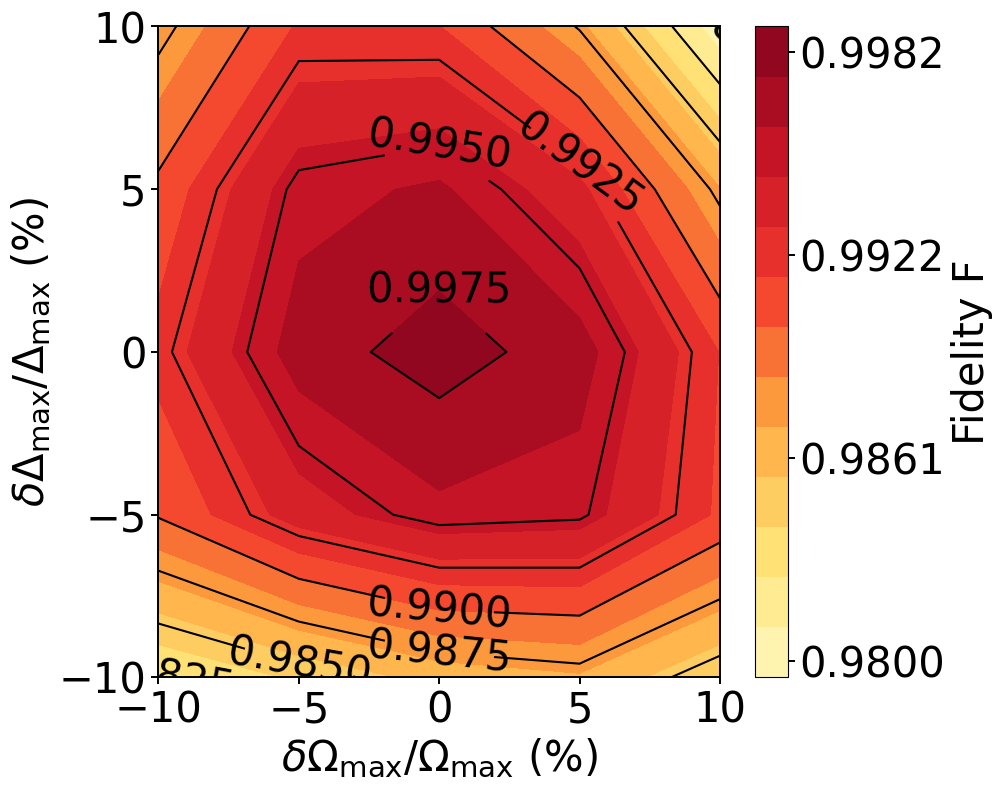

LCF: center=0.9982471401, min=0.9799983924, max=0.9982471401, elapsed=103.8s
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_LCF_robustness_fast_pm10.png
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_LCF_robustness_fast_pm10.pdf
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_LCF_robustness_fast_pm10.csv


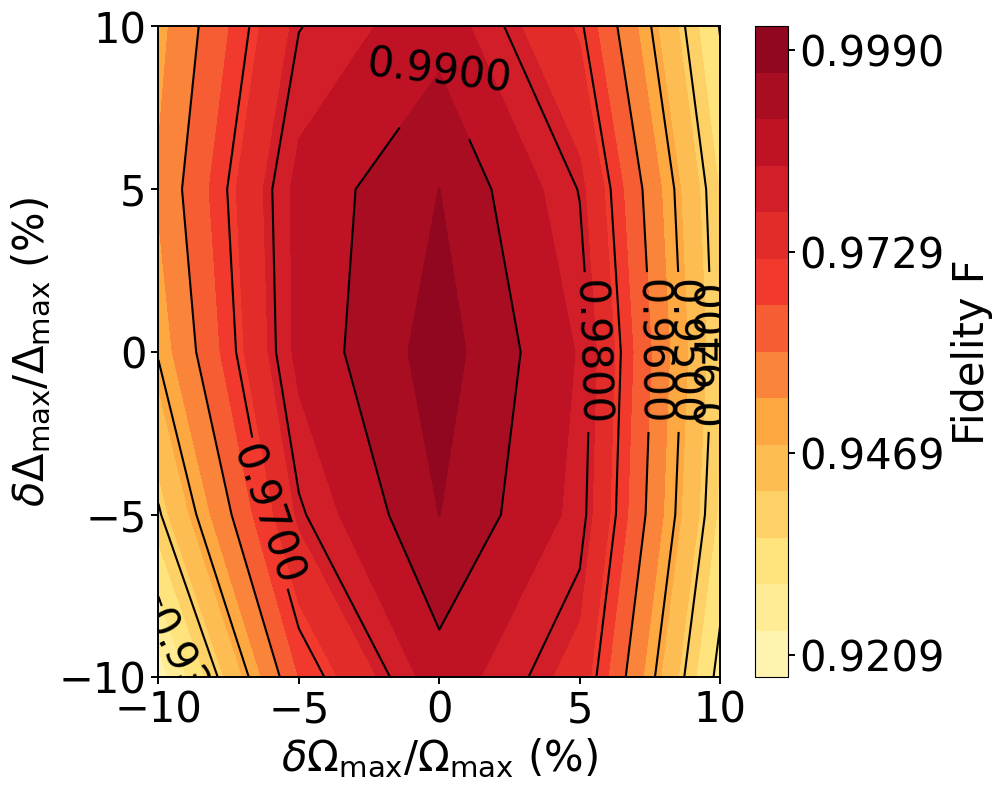

RAP: center=0.9989709148, min=0.9208628297, max=0.9989709148, elapsed=106.1s
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_RAP_robustness_fast_pm10.png
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_RAP_robustness_fast_pm10.pdf
saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W4_RAP_robustness_fast_pm10.csv


In [7]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['4LFCRAPδΩΩ_pm10.py']
# -*- coding: utf-8 -*-

import argparse
from itertools import product
from pathlib import Path
import time

import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.ticker as mticker
import numpy as np


OUT = Path.cwd()
N_ATOMS = 4
N_GRID = 5
ERROR_RANGE = 10.0
N_STEPS_FAST = 800

Omega0 = 2.0 * np.pi * 100.0
gamma_r = 1.0 / 540.0
Gamma = gamma_r / Omega0
Gamma_spont = Gamma / 16.0
Gamma_deph = 7.0 * Gamma / 8.0

# 参数来自用户给出的两个 w4_panel_*_wd.py 程序。
PARAMS = {
    "lcf": {
        "tau": 801.2260,
        "tau_r": 105.9039,
        "tau_d": 235.4821,
        "delta": 0.0700,
        "omega": 0.0473,
        "v0": 0.20,
        "pf": 0.5,
    },
    "rap": {
        "tau": 394.6934,
        "tau_r": 496.3033,
        "tau_d": 463.4327,
        "delta": 0.0853,
        "omega": 0.0267,
        "v0": 0.20,
        "pf": 0.5,
    },
}


# ==================== 4 比特 Hilbert 空间 ====================
states = ["".join(p) for p in product("01r", repeat=N_ATOMS)]
state_index = {state: i for i, state in enumerate(states)}
dim = len(states)
n_r = np.array([state.count("r") for state in states], dtype=float)
pair_count = n_r * (n_r - 1.0) / 2.0

g_perm = np.array([
    state_index[s.replace("0", "_").replace("1", "0").replace("_", "1")]
    for s in states
])

psi0 = np.zeros(dim, dtype=complex)
psi0[state_index["1111"]] = 1.0
psiT = np.zeros(dim, dtype=complex)
for state, i in state_index.items():
    if state.count("1") == 1 and state.count("r") == 0:
        psiT[i] = 0.5

coupling_maps = []
for atom in range(N_ATOMS):
    src = np.array([i for i, s in enumerate(states) if s[atom] in ("1", "r")])
    dst = np.array([
        state_index[
            states[i][:atom]
            + ("r" if states[i][atom] == "1" else "1")
            + states[i][atom + 1:]
        ]
        for i in src
    ])
    coupling_maps.append((src, dst))

spont_maps = []
for atom in range(N_ATOMS):
    src = np.array([i for i, s in enumerate(states) if s[atom] == "r"])
    for channel in ("0", "1"):
        dst = np.array([
            state_index[states[i][:atom] + channel + states[i][atom + 1:]]
            for i in src
        ])
        spont_maps.append((src, dst))

nr_sum = n_r[:, None] + n_r[None, :]
nr_both = np.zeros((dim, dim), dtype=float)
for atom in range(N_ATOMS):
    occupied = np.array([1.0 if s[atom] == "r" else 0.0 for s in states])
    nr_both += occupied[:, None] * occupied[None, :]


def pulse(tau, scheme, p):
    """返回无量纲 LCF 或 RAP 包络。"""
    if scheme == "lcf":
        tau_pi = p["pf"] * p["tau"]
        center = np.where(
            tau <= tau_pi,
            tau_pi / 2.0,
            tau_pi + (p["tau"] - tau_pi) / 2.0,
        )
        x_r = (tau - center) / p["tau_r"]
        x_d = (tau - center) / p["tau_d"]
        omega_env = -np.sqrt(2.0 * np.e) * x_r * np.exp(-(x_r ** 2))
        delta_env = np.e * x_d ** 2 * np.exp(-(x_d ** 2))
        return omega_env, delta_env

    a = np.exp(-(p["tau"] / (4.0 * p["tau_r"])) ** 4)
    segment = np.where(tau <= p["tau"] / 2.0, 1.0, 2.0)
    center = (2.0 * segment - 1.0) * p["tau"] / 4.0
    sign = np.where(segment == 1.0, 1.0, -1.0)
    omega_env = (
        np.exp(-((tau - center) / p["tau_r"]) ** 4) - a
    ) / (1.0 - a)
    delta_env = sign * np.sin(np.pi * (tau - center) / p["tau_d"])
    return omega_env, delta_env


def deriv(rho, omega_value, delta_value, v0):
    """与 4比特W.txt 等价的稀疏 Lindblad 右端。"""
    diag_h = delta_value[:, None] * n_r[None, :] + v0 * pair_count[None, :]
    coupling_comm = np.zeros_like(rho)
    for src, dst in coupling_maps:
        coupling_comm[:, dst, :] += 0.5 * rho[:, src, :]
        coupling_comm[:, :, dst] -= 0.5 * rho[:, :, src]

    dr = -1j * (
        (diag_h[:, :, None] - diag_h[:, None, :]) * rho
        + omega_value[:, None, None] * coupling_comm
    )
    dr += (
        -Gamma_spont * nr_sum[None]
        + Gamma_deph * (nr_both[None] - 0.5 * nr_sum[None])
    ) * rho
    for src, dst in spont_maps:
        dr[:, dst[:, None], dst[None, :]] += (
            Gamma_spont * rho[:, src[:, None], src[None, :]]
        )
    return dr


def fidelity_grid(scheme, offsets):
    """一次批量传播整个误差网格。"""
    p = PARAMS[scheme]
    d_omega, d_delta = np.meshgrid(offsets, offsets, indexing="xy")
    omega_peak = p["omega"] * (1.0 + d_omega.ravel() / 100.0)
    delta_peak = p["delta"] * (1.0 + d_delta.ravel() / 100.0)
    batch = omega_peak.size

    dt = p["tau"] / N_STEPS_FAST
    half_step = N_STEPS_FAST // 2
    rho = np.zeros((batch, dim, dim), dtype=complex)
    rho[:] = np.outer(psi0, psi0.conj())

    for n in range(N_STEPS_FAST):
        t0 = n * dt
        om0, de0 = pulse(t0, scheme, p)
        omh, deh = pulse(t0 + 0.5 * dt, scheme, p)
        om1, de1 = pulse(t0 + dt, scheme, p)

        k1 = deriv(rho, om0 * omega_peak, de0 * delta_peak, p["v0"])
        k2 = deriv(
            rho + 0.5 * dt * k1,
            omh * omega_peak,
            deh * delta_peak,
            p["v0"],
        )
        k3 = deriv(
            rho + 0.5 * dt * k2,
            omh * omega_peak,
            deh * delta_peak,
            p["v0"],
        )
        k4 = deriv(
            rho + dt * k3,
            om1 * omega_peak,
            de1 * delta_peak,
            p["v0"],
        )
        rho += dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0

        if n == half_step - 1:
            rho = rho[:, g_perm[:, None], g_perm[None, :]]

    fidelity = np.real(np.einsum("i,gij,j->g", psiT.conj(), rho, psiT))
    return fidelity.reshape(N_GRID, N_GRID)


def clabel_once_per_level(ax, contours):
    levels, positions = [], []
    for level, segments in zip(contours.levels, contours.allsegs):
        valid = [segment for segment in segments if len(segment) >= 2]
        if not valid:
            continue
        segment = max(valid, key=len)
        point = segment[len(segment) // 2]
        levels.append(float(level))
        positions.append((float(point[0]), float(point[1])))
    if levels:
        ax.clabel(
            contours,
            levels=levels,
            manual=positions,
            fmt="%.4f",
            fontsize=30,
            colors="black",
            inline=True,
            inline_spacing=3,
        )


def plot_grid(scheme, offsets, grid):
    cmap = LinearSegmentedColormap.from_list("paper", [
        (1.000, 0.976, 0.737),
        (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247),
        (0.953, 0.231, 0.176),
        (0.780, 0.080, 0.150),
        (0.520, 0.015, 0.115),
    ])

    vmin = float(np.nanmin(grid))
    vmax = float(np.nanmax(grid))
    # 颜色划分保持不变: 仍由数据范围自动取 ~15 层
    fill_levels = mticker.MaxNLocator(nbins=15).tick_values(vmin, vmax)
    line_levels = mticker.MaxNLocator(8).tick_values(vmin, vmax)
    line_levels = line_levels[(line_levels > vmin) & (line_levels < vmax)]

    fig, ax = plt.subplots(figsize=(10, 8))
    filled = ax.contourf(offsets, offsets, grid, levels=fill_levels, cmap=cmap)
    contours = ax.contour(
        offsets,
        offsets,
        grid,
        levels=line_levels,
        colors="black",
        linewidths=1.5,
    )
    clabel_once_per_level(ax, contours)

    # 颜色标尺: 仍是 4 个刻度, 数值随新的 vmin/vmax 自动变化
    cbar = fig.colorbar(
        filled,
        ax=ax,
        ticks=np.linspace(vmin, vmax, 4),
    )
    cbar.ax.tick_params(labelsize=30, width=1.4, length=5)
    cbar.ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.4f"))
    cbar.set_label("Fidelity F", fontsize=30)

    ax.set_xlabel(r"$\delta\Omega_{\max}/\Omega_{\max}$ (%)", fontsize=30)
    ax.set_ylabel(r"$\delta\Delta_{\max}/\Delta_{\max}$ (%)", fontsize=30)
    # 刻度划分固定为 -10, -5, 0, 5, 10 (与 ±10% 的 5 点网格一致)
    ax.set_xticks([-10, -5, 0, 5, 10])
    ax.set_yticks([-10, -5, 0, 5, 10])
    ax.tick_params(axis="both", labelsize=30, width=1.4, length=5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.4)

    center = grid[N_GRID // 2, N_GRID // 2]
    fig.tight_layout()

    stem = f"W4_{scheme.upper()}_robustness_fast_pm10"
    png = OUT / f"{stem}.png"
    pdf = OUT / f"{stem}.pdf"
    csv = OUT / f"{stem}.csv"
    fig.savefig(png, dpi=200)
    fig.savefig(pdf)
    np.savetxt(csv, grid, delimiter=",", fmt="%.10f")
    display(fig)
    plt.close(fig)
    return png, pdf, csv, center, vmin, vmax


def run(scheme):
    offsets = np.linspace(-ERROR_RANGE, ERROR_RANGE, N_GRID)
    started = time.time()
    grid = fidelity_grid(scheme, offsets)
    outputs = plot_grid(scheme, offsets, grid)
    elapsed = time.time() - started
    print(
        f"{scheme.upper()}: center={outputs[3]:.10f}, "
        f"min={outputs[4]:.10f}, max={outputs[5]:.10f}, "
        f"elapsed={elapsed:.1f}s"
    )
    print(f"saved {outputs[0]}")
    print(f"saved {outputs[1]}")
    print(f"saved {outputs[2]}")


if __name__ == "__main__":
    parser = argparse.ArgumentParser()
    parser.add_argument("--scheme", choices=("lcf", "rap", "both"), default="both")
    args = parser.parse_args()
    schemes = ("lcf", "rap") if args.scheme == "both" else (args.scheme,)
    for selected in schemes:
        run(selected)


## 8. `3RAP_pm10_RAP-B.py`

  行 13/13 完成


RAP 3比特 中心点 F0 = 0.998907    +/-10% 网格: 中心 F=0.998907, 最小 F=0.939000


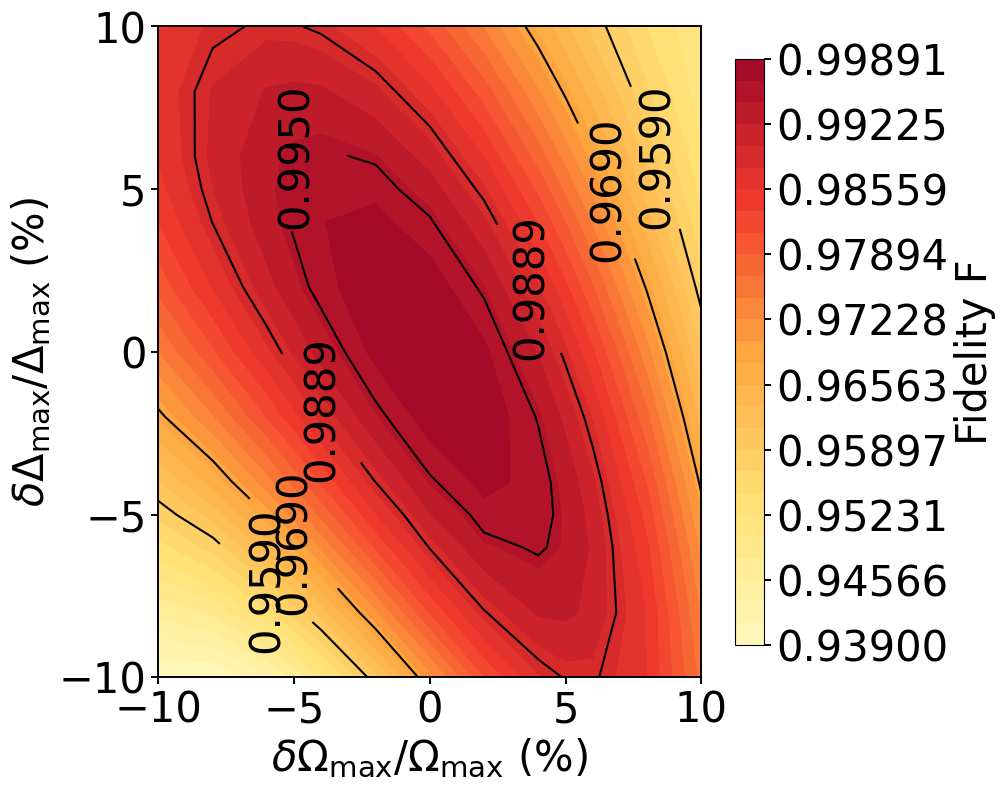

图已保存: paper_RAP_3bit_RAP-B_pm10_labels_fixed.png


In [8]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['3RAP_pm10_RAP-B.py']
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0        # Ω10 = 2π×100 MHz
gamma_r = 1.0/540.0            # 里德堡态总耗散率 (Cs |107P3/2>), 540 µs 寿命

# 无量纲耗散率
Gamma = gamma_r/Omega10
Gamma_spont = Gamma / 16.0     # 每通道自发辐射率 (r→0, r→1)
Gamma_deph  = 7.0 * Gamma / 8.0  # 退相位率

# ==================== 27 维 Hilbert 空间 (3 原子, W 态) ====================
N = 3
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

Cc = np.zeros((d, d))                        # 耦合 Σ_a (|r><1|+h.c.)/2
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':
            Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r':
            Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)                            # 失谐项 (每个 r 计 1Δ)
Err = np.diag(n_r*(n_r-1)/2)                 # 相互作用 V0·C(n_r,2) (|rr⟩=1,|rrr⟩=3)
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])             # πg 置换 (0↔1)

psi0 = np.zeros(d, complex); psi0[idx['111']] = 1.0
psiT = np.zeros(d, complex)
for a in range(N):
    s = ['0']*N; s[a] = '1'
    psiT[idx[''.join(s)]] = 1/np.sqrt(N)

# ==================== Lindblad 跳跃算符（完整形式） ====================
L_ops = []
for a in range(N):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
for a in range(N):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))
LdL_list = [L.conj().T @ L for L in L_ops]


# ==================== 脉冲（归一化包络，峰值=1 / ±1） ====================
def make_pulse_lcf(tau_tot, sR, sD, PF):
    """无能级交叉脉冲（高斯导数型），框架自带形式。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        tau_pi = PF*tau_tot
        tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
        xR = (tau - tm)/sR
        xD = (tau - tm)/sD
        Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
        De = np.e*xD**2*np.exp(-xD**2)
        return Om, De
    return pulse

def make_pulse_rap(tau_tot, tau_R, tau_D):
    """两段绝热通道 RAP 脉冲（fig2ef_rap.py 形式，τR,τD 独立）。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        a = np.exp(-(tau_tot/(4*tau_R))**4)
        k = np.where(tau <= tau_tot/2, 1.0, 2.0)
        tk = (2*k - 1)*tau_tot/4.0
        sign = np.where(k == 1.0, 1.0, -1.0)
        Om = (np.exp(-((tau - tk)/tau_R)**4) - a)/(1.0 - a)
        De = sign*np.sin(np.pi*(tau - tk)/tau_D)
        return Om, De
    return pulse


# ==================== 含耗散保真度（RK4，相对误差 dO/dD %） ====================
def make_fidelity(tau_tot, OM1max, DE1max, V0, PF, pulse_fn, dt=1.0, diss=True):
    # 快速扫描：dt=1.0；用于快速生成鲁棒性图，不作为精确复核结果。
    def fidelity(dO=0.0, dD=0.0):
        dO = np.atleast_1d(np.asarray(dO, float))
        dD = np.atleast_1d(np.asarray(dD, float))
        OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)   # 有效峰值
        DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]

        def deriv(rho, Om, De):
            H = De[:, None, None]*DrG + Om[:, None, None]*CcG + ErrG
            dr = -1j*(H@rho - rho@H)
            if diss:
                for L, LdL in zip(L_ops, LdL_list):
                    Lc = L.conj().T
                    dr += (L[None] @ rho @ Lc[None]
                           - 0.5*(LdL[None] @ rho + rho @ LdL[None]))
            return dr

        N = int(round(tau_tot/dt))
        n_pi = int(round(PF*N))                 # 中点施加 πg
        rho = np.zeros((dO.size, d, d), complex)
        rho[:, idx['111'], idx['111']] = 1.0
        for n in range(N):
            t0 = n*dt
            Om0, De0 = pulse_fn(t0)
            Omh, Deh = pulse_fn(t0+dt/2)
            Om1, De1 = pulse_fn(t0+dt)
            k1 = deriv(rho, Om0*OmM, De0*DeM)
            k2 = deriv(rho + 0.5*dt*k1, Omh*OmM, Deh*DeM)
            k3 = deriv(rho + 0.5*dt*k2, Omh*OmM, Deh*DeM)
            k4 = deriv(rho + dt*k3, Om1*OmM, De1*DeM)
            rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
            if n == n_pi - 1:
                rho = rho[:, g_perm[:, None], g_perm[None, :]]
        return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))
    return fidelity


# ==================== RAP 3比特参数: RAP-B (tau_D 减小版) ====================
# RAP-B: F0=0.998904 > LCF(0.998474); worst(±5%)=0.973107, worst(±10%)=0.939374
# 单位: 频率 x100 = MHz, 即 Omega10 = 2π×100 MHz
tau_tot = 925.381771          # = 1473 ns
tau_R, tau_D = 280.285837, 624.836536   # tau_D 由 1149 降到 625
PF      = 0.5
DE1max  = 0.072656923         # Δmax = 7.27 MHz
V0      = 0.20                # 20 MHz
OM1max  = 0.036328450         # Ωmax = 3.633 MHz   (Δmax/Ωmax = 2.00)
fid = make_fidelity(tau_tot=tau_tot, OM1max=OM1max, DE1max=DE1max,
                    V0=V0, PF=PF,
                    pulse_fn=make_pulse_rap(tau_tot, tau_R, tau_D), dt=1.0)


# ==================== ±10% 快速鲁棒性扫描 (13×13)，保留 ±5% 关键点 ====================
offsets = np.array([-10, -8, -6, -5, -4, -2, 0, 2, 4, 5, 6, 8, 10], float)

grid = np.zeros((len(offsets), len(offsets)))
for i, dD in enumerate(offsets):
    grid[i, :] = fid(dO=offsets, dD=dD)    # 行: δΔ0, 列: δΩmax
    print(f"  行 {i+1}/{len(offsets)} 完成", end='\r')
print()
F0 = fid()[0]
Fmin10 = grid.min()
ic = int(np.argmin(np.abs(offsets)))
print(f"RAP 3比特 中心点 F0 = {F0:.6f}    "
      f"+/-10% 网格: 中心 F={grid[ic,ic]:.6f}, "
      f"最小 F={Fmin10:.6f}")


# ==================== 画鲁棒性等高线图（论文形式） ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),   # 淡黄（低值）
    (1.000, 0.878, 0.451),   # 黄
    (0.992, 0.651, 0.247),   # 橙
    (0.953, 0.231, 0.176),   # 红橙
    (0.624, 0.031, 0.157),   # 深红（高值）
])
FS_LAB, FS_TCK = 30, 30
N_LINE = 5   # 比原图减少等高线数量，避免大字号标签拥挤

f_min = float(grid.min()); f_max = float(grid.max())
if np.isclose(f_min, f_max):
    pad = max(abs(f_min)*1e-6, 1e-9)
    f_min, f_max = f_min - pad, f_max + pad
fill_levels = np.linspace(f_min, f_max, 28)
# 原来的四条等高线（0.9590 / 0.9690 / 0.9789 / 0.9889）
line_levels = np.linspace(f_min, f_max, N_LINE + 2)[1:-1][1:]
# 去掉 0.9789 那条，改加一条 0.9950
line_levels = np.array([lv for lv in line_levels if abs(lv - 0.9789) > 2e-4]
                       + [0.9950])
line_levels.sort()

fig, ax = plt.subplots(figsize=(10, 8))
cf = ax.contourf(offsets, offsets, grid, levels=fill_levels, cmap=cmap_ref)
cs = ax.contour(offsets, offsets, grid, levels=line_levels,
                colors='black', linewidths=1.5)
# 标签仍嵌入等高线；自动选位后统一为同一竖直方向。
label_texts = ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black',
                       inline_spacing=3, rightside_up=True)
for txt in label_texts:
    txt.set_rotation(90)
    txt.set_rotation_mode('anchor')
ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
ax.set_ylabel(r'$\delta\Delta_{\max}/\Delta_{\max}$ (%)', fontsize=FS_LAB)
ax.set_xticks([-10, -5, 0, 5, 10])
ax.set_yticks([-10, -5, 0, 5, 10])
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)
cbar = fig.colorbar(cf, ax=ax, shrink=0.9)
cbar.set_label('Fidelity F', fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
plt.tight_layout()
plt.savefig('paper_RAP_3bit_RAP-B_pm10_labels_fixed.png', dpi=300)
display(fig)
plt.close(fig)
print("图已保存: paper_RAP_3bit_RAP-B_pm10_labels_fixed.png")


## 9. `3RAPdv.py`

[rap-dv] grid=(22, 22) pts=484 用时 7s Fmax=0.998949


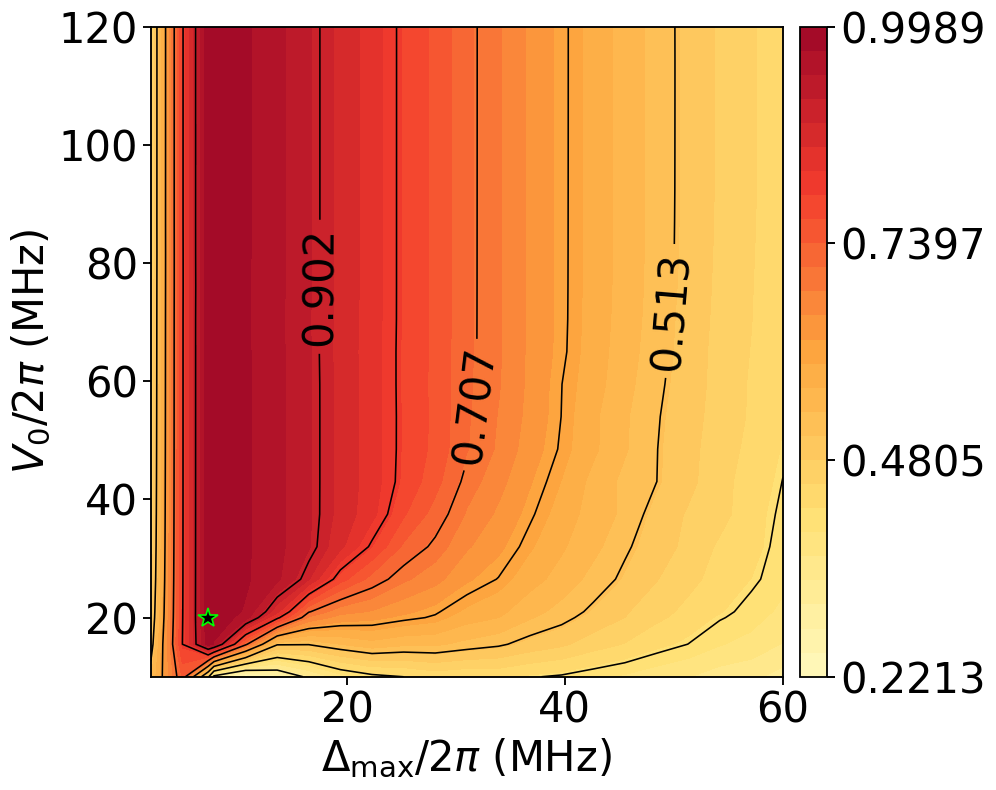

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W3_RAP_Delta_V.png


In [9]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['3RAPdv.py']
# -*- coding: utf-8 -*-
import os
import sys
import time
from itertools import product

import numpy as np
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# ===================== 物理内核: 3 比特 Lindblad 主方程 (27 维) =====================
# 时间以 Omega10 = 2*pi*100 MHz 为单位; 频率同理 (x100 = MHz)
OMEGA10      = 2.0 * np.pi * 100.0
GAMMA        = (1.0 / 540.0) / OMEGA10
GAMMA_SPONT  = GAMMA / 16.0
GAMMA_DEPH   = 7.0 * GAMMA / 8.0

NATOM  = 3
STATES = ["".join(s) for s in product("01r", repeat=NATOM)]
IDX    = {s: i for i, s in enumerate(STATES)}
DIM    = len(STATES)

COUPLING = np.zeros((DIM, DIM), dtype=complex)
for s, i in IDX.items():
    for a in range(NATOM):
        if s[a] == "1":
            tgt = s[:a] + "r" + s[a + 1:]
        elif s[a] == "r":
            tgt = s[:a] + "1" + s[a + 1:]
        else:
            continue
        COUPLING[IDX[tgt], i] = 0.5

N_R       = np.array([s.count("r") for s in STATES], dtype=float)
N_R_PAIRS = N_R * (N_R - 1.0) / 2.0
DIAG      = np.arange(DIM)
SWAP      = np.array([IDX[s.replace("0", "_").replace("1", "0").replace("_", "1")]
                      for s in STATES])

PSI0 = np.zeros(DIM, dtype=complex)
PSI0[IDX["111"]] = 1.0
PSIT = np.zeros(DIM, dtype=complex)
for a in range(NATOM):
    s = ["0"] * NATOM
    s[a] = "1"
    PSIT[IDX["".join(s)]] = 1.0 / np.sqrt(NATOM)

SPONT = []
for a in range(NATOM):
    for ch in "01":
        src = np.array([i for s, i in IDX.items() if s[a] == "r"])
        dst = np.array([IDX[s[:a] + ch + s[a + 1:]]
                        for s, i in IDX.items() if s[a] == "r"])
        SPONT.append((src, dst))

DEPH_JUMP = np.zeros((DIM, DIM))
for a in range(NATOM):
    m = np.array([1.0 if s[a] == "r" else 0.0 for s in STATES])
    DEPH_JUMP += np.outer(m, m)
DEPH_JUMP *= GAMMA_DEPH
ANTICOM = GAMMA * (N_R[:, None] + N_R[None, :])


def envelopes(kind, tau, wR, wD, d0, om0, pf, nstep):
    """返回 (B, nstep) 的 Omega(t)、Delta(t) 与 pi 门所在步。"""
    tau = tau[:, None]
    t = (np.arange(nstep)[None, :] + 0.5) * tau / nstep
    if kind == "lcf":
        tpi = pf[:, None] * tau
        tm = np.where(t < tpi, tpi / 2.0, tpi + (tau - tpi) / 2.0)
        xr = (t - tm) / wR[:, None]
        xd = (t - tm) / wD[:, None]
        om = -om0[:, None] * np.sqrt(2.0 * np.e) * xr * np.exp(-xr ** 2)
        de = d0[:, None] * np.e * xd ** 2 * np.exp(-xd ** 2)
        swap = np.round(pf * nstep).astype(int)
    else:
        edge = np.exp(-((tau / (4.0 * wR[:, None])) ** 4))
        half = np.where(t <= tau / 2.0, 1.0, 2.0)
        tk = (2.0 * half - 1.0) * tau / 4.0
        sgn = np.where(half == 1.0, 1.0, -1.0)
        den = np.maximum(1.0 - edge, 1e-10)
        om = om0[:, None] * (np.exp(-((t - tk) / wR[:, None]) ** 4) - edge) / den
        de = d0[:, None] * sgn * np.sin(np.pi * (t - tk) / wD[:, None])
        swap = np.full(tau.shape[0], nstep // 2, dtype=int)
    return om, de, swap


def fidelity_batch(kind, P, nstep=220):
    """P: (B, 7) = [tau, tauR, tauD, Dmax, V0, Omax, PF]，返回 (B,) 保真度。"""
    P = np.atleast_2d(np.asarray(P, dtype=float))
    B = P.shape[0]
    tau, wR, wD, d0, v0, om0, pf = [P[:, i].copy() for i in range(7)]
    om, de, swap = envelopes(kind, tau, wR, wD, d0, om0, pf, nstep)
    H = om[:, :, None, None] * COUPLING[None, None, :, :]
    H[:, :, DIAG, DIAG] += (de[:, :, None] * N_R[None, None, :]
                            + v0[:, None, None] * N_R_PAIRS[None, None, :])
    w, v = np.linalg.eigh(H.reshape(-1, DIM, DIM))
    v = v.reshape(B, nstep, DIM, DIM)
    dt = tau / nstep
    phase = np.exp(-1j * w.reshape(B, nstep, 1, DIM)
                   * (0.5 * dt)[:, None, None, None])
    half = (v * phase) @ np.swapaxes(v.conj(), 2, 3)
    rho = np.zeros((B, DIM, DIM), dtype=complex)
    rho[:, IDX["111"], IDX["111"]] = 1.0
    for n in range(nstep):
        u = half[:, n]
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        jump = DEPH_JUMP[None] * rho
        for src, dst in SPONT:
            jump[:, dst[:, None], dst[None, :]] += \
                GAMMA_SPONT * rho[:, src[:, None], src[None, :]]
        rho += dt[:, None, None] * (jump - 0.5 * ANTICOM[None] * rho)
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        sel = np.where(n == swap - 1)[0]
        if sel.size:
            rho[sel] = rho[sel][:, SWAP, :][:, :, SWAP]
    return np.real(np.einsum("i,bij,j->b", PSIT.conj(), rho, PSIT))



# ===================== 本面板参数 =====================
KIND    = "rap"
TAU     = 925.3818     # 归一化门时间 (x0.15915 = ns)
TAUR    = 280.2858     # 上升段
TAUD    = 624.8365     # 下降段
D0_OPT  = 0.072657      # 最优 Delta_max (x100 = MHz)
V0_OPT  = 0.200000      # 最优 V0 (x100 = MHz)
OM_OPT  = 0.036328      # 最优 Omega_max (x100 = MHz)
PF      = 0.500000      # LCF 中点 pi 门占比
F_PEAK  = 0.998903   # 该方案中心保真度
F_WORST = 0.973155  # 该方案 +-5% 最坏保真度

OUTDIR = os.getcwd()
NPZ    = os.path.join(OUTDIR, "w3_rap_dv_grid.npz")
PNG    = os.path.join(OUTDIR, "W3_RAP_Delta_V.png")
CHUNK  = 16              # 每批并行传播的点数
NSTEP  = 120             # 传播步数 (哈密顿量部分精确对角化, 耗散一阶)
M      = 21              # 每方向网格数


def grid(a, b, n, extra):
    """与 3/4 比特图相同的坐标范围 + 最优点补点 (去重排序)。"""
    return np.unique(np.round(np.concatenate(
        [np.linspace(a, b, n), np.asarray(extra, float)]), 6))


def scan():
    t0 = time.time()
    base = np.array([TAU, TAUR, TAUD, D0_OPT, V0_OPT, OM_OPT, PF])
    a1 = grid(2.0, 60.0, M, [D0_OPT * 100.0])      # Delta_max (MHz)
    a2 = grid(10.0, 120.0, M, [V0_OPT * 100.0])    # V0 (MHz)
    A1, A2 = np.meshgrid(a1, a2, indexing="ij")
    flat = np.empty(A1.size)
    for i in range(0, A1.size, CHUNK):
        sl = slice(i, min(i + CHUNK, A1.size))
        P = np.tile(base, (sl.stop - sl.start, 1))
        P[:, 3] = A1.ravel()[sl] / 100.0
        P[:, 4] = A2.ravel()[sl] / 100.0
        flat[sl] = fidelity_batch(KIND, P, nstep=NSTEP)
    F = flat.reshape(A1.shape)
    print("[rap-dv] grid=%s pts=%d 用时 %.0fs Fmax=%.6f" %
          (F.shape, F.size, time.time() - t0, np.nanmax(F)), flush=True)
    star = np.array([D0_OPT*100.0, V0_OPT*100.0])
    np.savez(NPZ, a1=A1, a2=A2, F=F, star=star)
    return A1, A2, F, star


def plot(X, Y, F, star):
    fmin, fmax = float(np.nanmin(F)), float(np.nanmax(F))
    cmap = LinearSegmentedColormap.from_list("ref_yor", [
        (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
        (0.624, 0.031, 0.157),
    ])
    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(X, Y, F, levels=np.linspace(fmin, fmax, 28), cmap=cmap)
    lines = np.linspace(fmin, fmax, 9)[1:-1]
    cs = ax.contour(X, Y, F, levels=lines, colors="black", linewidths=1.15)
    ax.clabel(cs, fmt="%.3f", fontsize=30, inline=True, inline_spacing=4,
              manual=[(17.0, 76.0), (31.0, 56.0), (49.0, 72.0)])
    ax.plot(star[0], star[1], "*", ms=15, color="black",
            markeredgecolor="lime", markeredgewidth=1.2)
    cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                      pad=0.025, fraction=0.055, aspect=24)
    cb.ax.tick_params(labelsize=30, width=1.4, length=6)
    cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
    cb.outline.set_linewidth(1.3)
    ax.set_xlabel(r"$\Delta_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_ylabel(r"$V_0/2\pi$ (MHz)", fontsize=30)
    ax.set_xlim(2.0, 60.0)
    ax.set_ylim(10.0, 120.0)
    ax.tick_params(axis="both", labelsize=30, width=1.35, length=5.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.35)
    fig.tight_layout()
    fig.savefig(PNG, dpi=200)
    display(fig)
    plt.close(fig)
    print("saved " + PNG)


if __name__ == "__main__":
    force = (len(sys.argv) > 1 and sys.argv[1] == "rescan")
    if os.path.exists(NPZ) and not force:
        d = np.load(NPZ)
        X, Y, F, star = d["a1"], d["a2"], d["F"], d["star"]
        print("loaded " + NPZ)
    else:
        X, Y, F, star = scan()
    plot(X, Y, F, star)


## 10. `3ARAPOD.py`

[rap-wd] grid=(22, 22) pts=484 用时 7s Fmax=0.998866


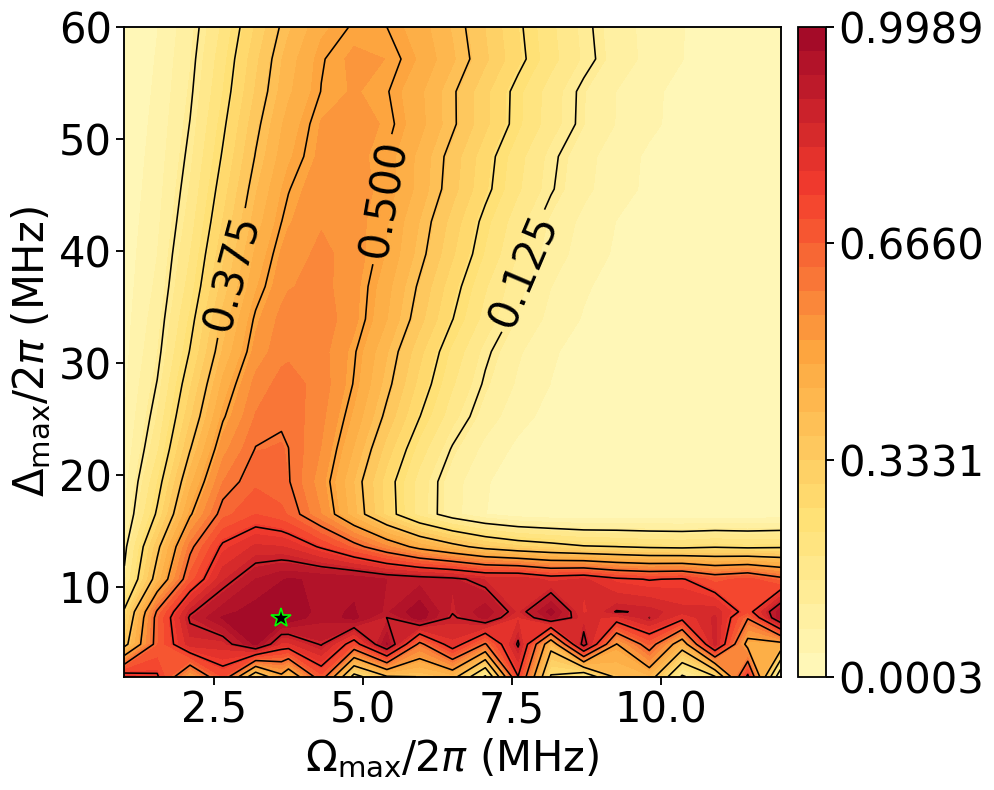

saved C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\W3_RAP_Omega_Delta.png


In [10]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['3ARAPOD.py']
# -*- coding: utf-8 -*-
import os
import sys
import time
from itertools import product

import numpy as np
import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


# ===================== 物理内核: 3 比特 Lindblad 主方程 (27 维) =====================
# 时间以 Omega10 = 2*pi*100 MHz 为单位; 频率同理 (x100 = MHz)
OMEGA10      = 2.0 * np.pi * 100.0
GAMMA        = (1.0 / 540.0) / OMEGA10
GAMMA_SPONT  = GAMMA / 16.0
GAMMA_DEPH   = 7.0 * GAMMA / 8.0

NATOM  = 3
STATES = ["".join(s) for s in product("01r", repeat=NATOM)]
IDX    = {s: i for i, s in enumerate(STATES)}
DIM    = len(STATES)

COUPLING = np.zeros((DIM, DIM), dtype=complex)
for s, i in IDX.items():
    for a in range(NATOM):
        if s[a] == "1":
            tgt = s[:a] + "r" + s[a + 1:]
        elif s[a] == "r":
            tgt = s[:a] + "1" + s[a + 1:]
        else:
            continue
        COUPLING[IDX[tgt], i] = 0.5

N_R       = np.array([s.count("r") for s in STATES], dtype=float)
N_R_PAIRS = N_R * (N_R - 1.0) / 2.0
DIAG      = np.arange(DIM)
SWAP      = np.array([IDX[s.replace("0", "_").replace("1", "0").replace("_", "1")]
                      for s in STATES])

PSI0 = np.zeros(DIM, dtype=complex)
PSI0[IDX["111"]] = 1.0
PSIT = np.zeros(DIM, dtype=complex)
for a in range(NATOM):
    s = ["0"] * NATOM
    s[a] = "1"
    PSIT[IDX["".join(s)]] = 1.0 / np.sqrt(NATOM)

SPONT = []
for a in range(NATOM):
    for ch in "01":
        src = np.array([i for s, i in IDX.items() if s[a] == "r"])
        dst = np.array([IDX[s[:a] + ch + s[a + 1:]]
                        for s, i in IDX.items() if s[a] == "r"])
        SPONT.append((src, dst))

DEPH_JUMP = np.zeros((DIM, DIM))
for a in range(NATOM):
    m = np.array([1.0 if s[a] == "r" else 0.0 for s in STATES])
    DEPH_JUMP += np.outer(m, m)
DEPH_JUMP *= GAMMA_DEPH
ANTICOM = GAMMA * (N_R[:, None] + N_R[None, :])


def envelopes(kind, tau, wR, wD, d0, om0, pf, nstep):
    """返回 (B, nstep) 的 Omega(t)、Delta(t) 与 pi 门所在步。"""
    tau = tau[:, None]
    t = (np.arange(nstep)[None, :] + 0.5) * tau / nstep
    if kind == "lcf":
        tpi = pf[:, None] * tau
        tm = np.where(t < tpi, tpi / 2.0, tpi + (tau - tpi) / 2.0)
        xr = (t - tm) / wR[:, None]
        xd = (t - tm) / wD[:, None]
        om = -om0[:, None] * np.sqrt(2.0 * np.e) * xr * np.exp(-xr ** 2)
        de = d0[:, None] * np.e * xd ** 2 * np.exp(-xd ** 2)
        swap = np.round(pf * nstep).astype(int)
    else:
        edge = np.exp(-((tau / (4.0 * wR[:, None])) ** 4))
        half = np.where(t <= tau / 2.0, 1.0, 2.0)
        tk = (2.0 * half - 1.0) * tau / 4.0
        sgn = np.where(half == 1.0, 1.0, -1.0)
        den = np.maximum(1.0 - edge, 1e-10)
        om = om0[:, None] * (np.exp(-((t - tk) / wR[:, None]) ** 4) - edge) / den
        de = d0[:, None] * sgn * np.sin(np.pi * (t - tk) / wD[:, None])
        swap = np.full(tau.shape[0], nstep // 2, dtype=int)
    return om, de, swap


def fidelity_batch(kind, P, nstep=220):
    """P: (B, 7) = [tau, tauR, tauD, Dmax, V0, Omax, PF]，返回 (B,) 保真度。"""
    P = np.atleast_2d(np.asarray(P, dtype=float))
    B = P.shape[0]
    tau, wR, wD, d0, v0, om0, pf = [P[:, i].copy() for i in range(7)]
    om, de, swap = envelopes(kind, tau, wR, wD, d0, om0, pf, nstep)
    H = om[:, :, None, None] * COUPLING[None, None, :, :]
    H[:, :, DIAG, DIAG] += (de[:, :, None] * N_R[None, None, :]
                            + v0[:, None, None] * N_R_PAIRS[None, None, :])
    w, v = np.linalg.eigh(H.reshape(-1, DIM, DIM))
    v = v.reshape(B, nstep, DIM, DIM)
    dt = tau / nstep
    phase = np.exp(-1j * w.reshape(B, nstep, 1, DIM)
                   * (0.5 * dt)[:, None, None, None])
    half = (v * phase) @ np.swapaxes(v.conj(), 2, 3)
    rho = np.zeros((B, DIM, DIM), dtype=complex)
    rho[:, IDX["111"], IDX["111"]] = 1.0
    for n in range(nstep):
        u = half[:, n]
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        jump = DEPH_JUMP[None] * rho
        for src, dst in SPONT:
            jump[:, dst[:, None], dst[None, :]] += \
                GAMMA_SPONT * rho[:, src[:, None], src[None, :]]
        rho += dt[:, None, None] * (jump - 0.5 * ANTICOM[None] * rho)
        rho = u @ rho @ u.conj().transpose(0, 2, 1)
        sel = np.where(n == swap - 1)[0]
        if sel.size:
            rho[sel] = rho[sel][:, SWAP, :][:, :, SWAP]
    return np.real(np.einsum("i,bij,j->b", PSIT.conj(), rho, PSIT))



# ===================== 本面板参数 =====================
KIND    = "rap"
TAU     = 925.3818     # 归一化门时间 (x0.15915 = ns)
TAUR    = 280.2858     # 上升段
TAUD    = 624.8365     # 下降段
D0_OPT  = 0.072657      # 最优 Delta_max (x100 = MHz)
V0_OPT  = 0.200000      # 最优 V0 (x100 = MHz)
OM_OPT  = 0.036328      # 最优 Omega_max (x100 = MHz)
PF      = 0.500000      # LCF 中点 pi 门占比
F_PEAK  = 0.998903   # 该方案中心保真度
F_WORST = 0.973155  # 该方案 +-5% 最坏保真度

OUTDIR = os.getcwd()
NPZ    = os.path.join(OUTDIR, "w3_rap_wd_grid.npz")
PNG    = os.path.join(OUTDIR, "W3_RAP_Omega_Delta.png")
CHUNK  = 16              # 每批并行传播的点数
NSTEP  = 120             # 传播步数 (哈密顿量部分精确对角化, 耗散一阶)
M      = 21              # 每方向网格数


def grid(a, b, n, extra):
    """与 3/4 比特图相同的坐标范围 + 最优点补点 (去重排序)。"""
    return np.unique(np.round(np.concatenate(
        [np.linspace(a, b, n), np.asarray(extra, float)]), 6))


def scan():
    t0 = time.time()
    base = np.array([TAU, TAUR, TAUD, D0_OPT, V0_OPT, OM_OPT, PF])
    a1 = grid(1.0, 12.0, M, [OM_OPT * 100.0])      # Omega_max (MHz)
    a2 = grid(2.0, 60.0, M, [D0_OPT * 100.0])      # Delta_max (MHz)
    A1, A2 = np.meshgrid(a1, a2, indexing="ij")
    flat = np.empty(A1.size)
    for i in range(0, A1.size, CHUNK):
        sl = slice(i, min(i + CHUNK, A1.size))
        P = np.tile(base, (sl.stop - sl.start, 1))
        P[:, 5] = A1.ravel()[sl] / 100.0
        P[:, 3] = A2.ravel()[sl] / 100.0
        flat[sl] = fidelity_batch(KIND, P, nstep=NSTEP)
    F = flat.reshape(A1.shape)
    print("[rap-wd] grid=%s pts=%d 用时 %.0fs Fmax=%.6f" %
          (F.shape, F.size, time.time() - t0, np.nanmax(F)), flush=True)
    star = np.array([OM_OPT*100.0, D0_OPT*100.0])
    np.savez(NPZ, a1=A1, a2=A2, F=F, star=star)
    return A1, A2, F, star


def plot(X, Y, F, star):
    fmin, fmax = float(np.nanmin(F)), float(np.nanmax(F))
    cmap = LinearSegmentedColormap.from_list("ref_yor", [
        (1.000, 0.976, 0.737), (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247), (0.953, 0.231, 0.176),
        (0.624, 0.031, 0.157),
    ])
    fig, ax = plt.subplots(figsize=(10, 8))
    cf = ax.contourf(X, Y, F, levels=np.linspace(fmin, fmax, 28), cmap=cmap)
    lines = np.linspace(fmin, fmax, 9)[1:-1]
    cs = ax.contour(X, Y, F, levels=lines, colors="black", linewidths=1.15)
    ax.clabel(cs, fmt="%.3f", fontsize=30, inline=True, inline_spacing=4,
              manual=[(2.8, 38.0), (5.6, 44.0), (8.8, 34.0)])
    ax.plot(star[0], star[1], "*", ms=15, color="black",
            markeredgecolor="lime", markeredgewidth=1.2)
    cb = fig.colorbar(cf, ax=ax, ticks=np.linspace(fmin, fmax, 4),
                      pad=0.025, fraction=0.055, aspect=24)
    cb.ax.tick_params(labelsize=30, width=1.4, length=6)
    cb.ax.yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.4f"))
    cb.outline.set_linewidth(1.3)
    ax.set_xlabel(r"$\Omega_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_ylabel(r"$\Delta_{\max}/2\pi$ (MHz)", fontsize=30)
    ax.set_xlim(1.0, 12.0)
    ax.set_ylim(2.0, 60.0)
    ax.tick_params(axis="both", labelsize=30, width=1.35, length=5.5)
    for spine in ax.spines.values():
        spine.set_linewidth(1.35)
    fig.tight_layout()
    fig.savefig(PNG, dpi=200)
    display(fig)
    plt.close(fig)
    print("saved " + PNG)


if __name__ == "__main__":
    force = (len(sys.argv) > 1 and sys.argv[1] == "rescan")
    if os.path.exists(NPZ) and not force:
        d = np.load(NPZ)
        X, Y, F, star = d["a1"], d["a2"], d["F"], d["star"]
        print("loaded " + NPZ)
    else:
        X, Y, F, star = scan()
    plot(X, Y, F, star)


## 11. `3比特LFCδΩδΔ_fast_pm10_notitle.txt`

  行 13/13 完成


LCF 3比特 中心点 F0 = 0.997650    +/-10% 网格: 中心 F=0.997650, 最小 F=0.978444


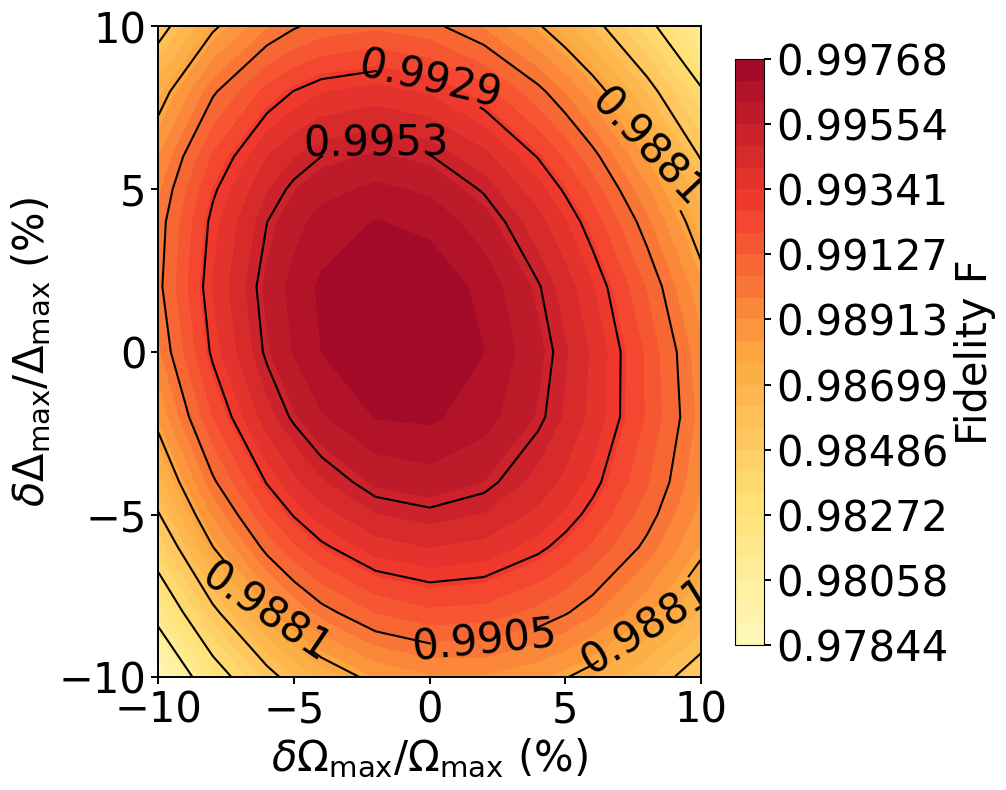

图已保存: paper_LCF_3bit_fast_opt_notitle.png


In [11]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['3比特LFCδΩδΔ_fast_pm10_notitle.txt']
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from itertools import product

# ==================== 物理参数 (2π×MHz 与 µs) ====================
Omega10 = 2*np.pi*100.0        # Ω10 = 2π×100 MHz
gamma_r = 1.0/540.0            # 里德堡态总耗散率 (Cs |107P3/2>), 540 µs 寿命

# 无量纲耗散率
Gamma = gamma_r/Omega10
Gamma_spont = Gamma / 16.0     # 每通道自发辐射率 (r→0, r→1)
Gamma_deph  = 7.0 * Gamma / 8.0  # 退相位率

# ==================== 27 维 Hilbert 空间 (3 原子, W 态) ====================
N = 3
st = [''.join(p) for p in product('01r', repeat=N)]
idx = {s: i for i, s in enumerate(st)}
d = len(st)

Cc = np.zeros((d, d))                        # 耦合 Σ_a (|r><1|+h.c.)/2
for s, i in idx.items():
    for a in range(N):
        if s[a] == '1':
            Cc[idx[s[:a]+'r'+s[a+1:]], i] = 0.5
        elif s[a] == 'r':
            Cc[idx[s[:a]+'1'+s[a+1:]], i] = 0.5
n_r = np.array([s.count('r') for s in st], float)
Dr = np.diag(n_r)                            # 失谐项 (每个 r 计 1Δ)
Err = np.diag(n_r*(n_r-1)/2)                 # 相互作用 V0·C(n_r,2) (|rr⟩=1,|rrr⟩=3)
g_perm = np.array([idx[s.replace('0', '_').replace('1', '0').replace('_', '1')]
                   for s in st])             # πg 置换 (0↔1)

psi0 = np.zeros(d, complex); psi0[idx['111']] = 1.0
psiT = np.zeros(d, complex)
for a in range(N):
    s = ['0']*N; s[a] = '1'
    psiT[idx[''.join(s)]] = 1/np.sqrt(N)

# ==================== Lindblad 跳跃算符（完整形式） ====================
L_ops = []
for a in range(N):
    for ch in ('0', '1'):
        L = np.zeros((d, d), dtype=complex)
        for s, i in idx.items():
            if s[a] == 'r':
                j = idx[s[:a]+ch+s[a+1:]]
                L[j, i] = np.sqrt(Gamma_spont)
        L_ops.append(L)
for a in range(N):
    diag = np.array([1.0 if s[a] == 'r' else 0.0 for s in st], dtype=float)
    L_ops.append(np.sqrt(Gamma_deph) * np.diag(diag))
LdL_list = [L.conj().T @ L for L in L_ops]


# ==================== 脉冲（归一化包络，峰值=1 / ±1） ====================
def make_pulse_lcf(tau_tot, sR, sD, PF):
    """无能级交叉脉冲（高斯导数型），框架自带形式。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        tau_pi = PF*tau_tot
        tm = np.where(tau <= tau_pi, tau_pi/2, tau_pi + (tau_tot - tau_pi)/2)
        xR = (tau - tm)/sR
        xD = (tau - tm)/sD
        Om = -np.sqrt(2*np.e)*xR*np.exp(-xR**2)
        De = np.e*xD**2*np.exp(-xD**2)
        return Om, De
    return pulse

def make_pulse_rap(tau_tot, tau_R, tau_D):
    """两段绝热通道 RAP 脉冲（fig2ef_rap.py 形式，τR,τD 独立）。"""
    def pulse(tau):
        tau = np.asarray(tau, float)
        a = np.exp(-(tau_tot/(4*tau_R))**4)
        k = np.where(tau <= tau_tot/2, 1.0, 2.0)
        tk = (2*k - 1)*tau_tot/4.0
        sign = np.where(k == 1.0, 1.0, -1.0)
        Om = (np.exp(-((tau - tk)/tau_R)**4) - a)/(1.0 - a)
        De = sign*np.sin(np.pi*(tau - tk)/tau_D)
        return Om, De
    return pulse


# ==================== 含耗散保真度（RK4，相对误差 dO/dD %） ====================
def make_fidelity(tau_tot, OM1max, DE1max, V0, PF, pulse_fn, dt=1.0, diss=True):
    # 快速扫描：dt=1.0；用于快速生成鲁棒性图，不作为精确复核结果。
    def fidelity(dO=0.0, dD=0.0):
        dO = np.atleast_1d(np.asarray(dO, float))
        dD = np.atleast_1d(np.asarray(dD, float))
        OmM, DeM = OM1max*(1+dO/100), DE1max*(1+dD/100)   # 有效峰值
        DrG, CcG, ErrG = Dr[None], Cc[None], V0*Err[None]

        def deriv(rho, Om, De):
            H = De[:, None, None]*DrG + Om[:, None, None]*CcG + ErrG
            dr = -1j*(H@rho - rho@H)
            if diss:
                for L, LdL in zip(L_ops, LdL_list):
                    Lc = L.conj().T
                    dr += (L[None] @ rho @ Lc[None]
                           - 0.5*(LdL[None] @ rho + rho @ LdL[None]))
            return dr

        N = int(round(tau_tot/dt))
        n_pi = int(round(PF*N))                 # 中点施加 πg
        rho = np.zeros((dO.size, d, d), complex)
        rho[:, idx['111'], idx['111']] = 1.0
        for n in range(N):
            t0 = n*dt
            Om0, De0 = pulse_fn(t0)
            Omh, Deh = pulse_fn(t0+dt/2)
            Om1, De1 = pulse_fn(t0+dt)
            k1 = deriv(rho, Om0*OmM, De0*DeM)
            k2 = deriv(rho + 0.5*dt*k1, Omh*OmM, Deh*DeM)
            k3 = deriv(rho + 0.5*dt*k2, Omh*OmM, Deh*DeM)
            k4 = deriv(rho + dt*k3, Om1*OmM, De1*DeM)
            rho = rho + dt*(k1 + 2*k2 + 2*k3 + k4)/6
            if n == n_pi - 1:
                rho = rho[:, g_perm[:, None], g_perm[None, :]]
        return np.real(np.einsum('i,gij,j->g', psiT.conj(), rho, psiT))
    return fidelity


# ==================== LCF 3比特最优参数 (Ωmax<5MHz 优化) ====================
# 当前 LCF 最优参数（Ωmax<5 MHz）
tau_tot = 1012.1256479972835
sR, sD  = 134.5721346458133, 453.3152082992042
PF      = 0.5404225914592502
DE1max  = 0.16543188912172252
V0      = 0.19881826786424547
OM1max  = 0.0385313033102552
fid = make_fidelity(tau_tot=tau_tot, OM1max=OM1max, DE1max=DE1max,
                    V0=V0, PF=PF,
                    pulse_fn=make_pulse_lcf(tau_tot, sR, sD, PF), dt=1.0)


# ==================== ±10% 快速鲁棒性扫描 (13×13)，保留 ±5% 关键点 ====================
offsets = np.array([-10, -8, -6, -5, -4, -2, 0, 2, 4, 5, 6, 8, 10], float)

grid = np.zeros((len(offsets), len(offsets)))
for i, dD in enumerate(offsets):
    grid[i, :] = fid(dO=offsets, dD=dD)    # 行: δΔ0, 列: δΩmax
    print(f"  行 {i+1}/{len(offsets)} 完成", end='\r')
print()
F0 = fid()[0]
Fmin10 = grid.min()
ic = int(np.argmin(np.abs(offsets)))
print(f"LCF 3比特 中心点 F0 = {F0:.6f}    "
      f"+/-10% 网格: 中心 F={grid[ic,ic]:.6f}, "
      f"最小 F={Fmin10:.6f}")


# ==================== 画鲁棒性等高线图（论文形式） ====================
cmap_ref = LinearSegmentedColormap.from_list('ref_yor', [
    (1.000, 0.976, 0.737),   # 淡黄（低值）
    (1.000, 0.878, 0.451),   # 黄
    (0.992, 0.651, 0.247),   # 橙
    (0.953, 0.231, 0.176),   # 红橙
    (0.624, 0.031, 0.157),   # 深红（高值）
])
FS_LAB, FS_TCK = 30, 30
N_LINE = 9   # 等高线根数（均匀分布在自身数据范围内）

f_min = float(grid.min()); f_max = float(grid.max())
if np.isclose(f_min, f_max):
    pad = max(abs(f_min)*1e-6, 1e-9)
    f_min, f_max = f_min - pad, f_max + pad
fill_levels = np.linspace(f_min, f_max, 28)
line_levels = np.linspace(f_min, f_max, N_LINE)

fig, ax = plt.subplots(figsize=(10, 8))
cf = ax.contourf(offsets, offsets, grid, levels=fill_levels, cmap=cmap_ref)
cs = ax.contour(offsets, offsets, grid, levels=line_levels,
                colors='black', linewidths=1.5)
ax.clabel(cs, fmt='%.4f', fontsize=30, colors='black', inline_spacing=3)
ax.set_xlabel(r'$\delta\Omega_{\max}/\Omega_{\max}$ (%)', fontsize=FS_LAB)
ax.set_ylabel(r'$\delta\Delta_{\max}/\Delta_{\max}$ (%)', fontsize=FS_LAB)
ax.set_xticks([-10, -5, 0, 5, 10])
ax.set_yticks([-10, -5, 0, 5, 10])
ax.tick_params(axis='both', labelsize=FS_TCK, width=1.4, length=5)
for sp in ax.spines.values():
    sp.set_linewidth(1.4)
cbar = fig.colorbar(cf, ax=ax, shrink=0.9)
cbar.set_label('Fidelity F', fontsize=FS_LAB)
cbar.ax.tick_params(labelsize=FS_TCK, width=1.4, length=5)
plt.tight_layout()
plt.savefig('paper_LCF_3bit_fast_opt_notitle.png', dpi=300)
display(fig)
plt.close(fig)
print("图已保存: paper_LCF_3bit_fast_opt_notitle.png")


## 12. `已粘贴的文本.txt`（快速扫描、无标题）

扫描 LCF 的 (Delta_max, V0)...


扫描 LCF 的 (Omega_max, Delta_max)...


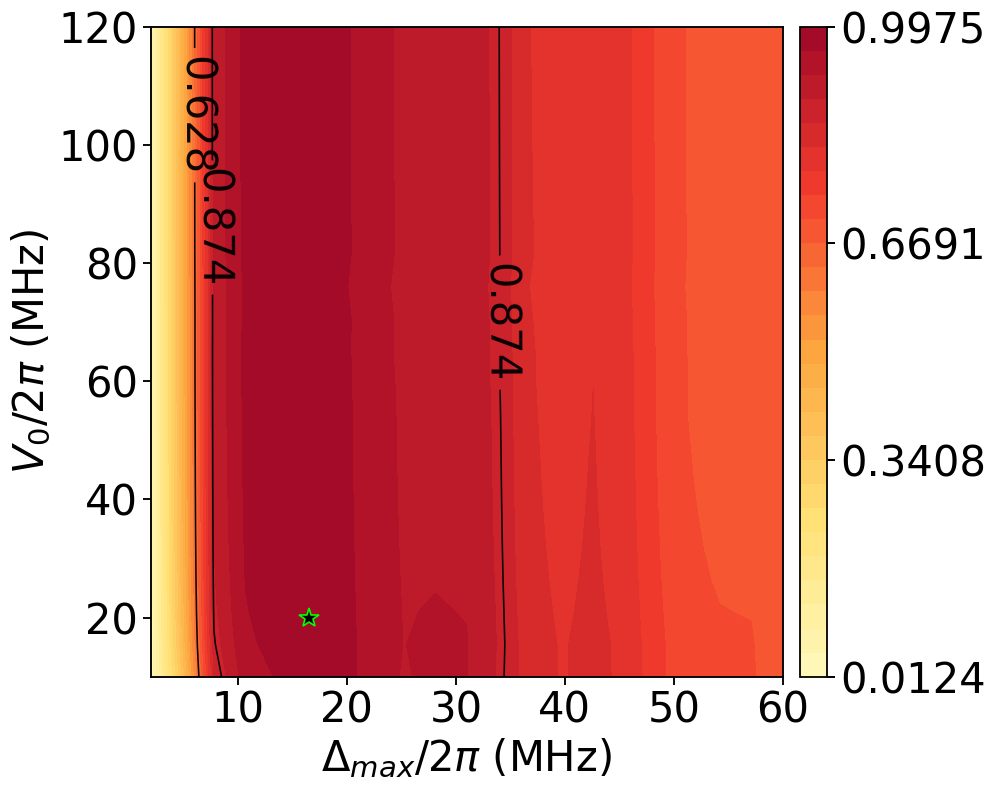

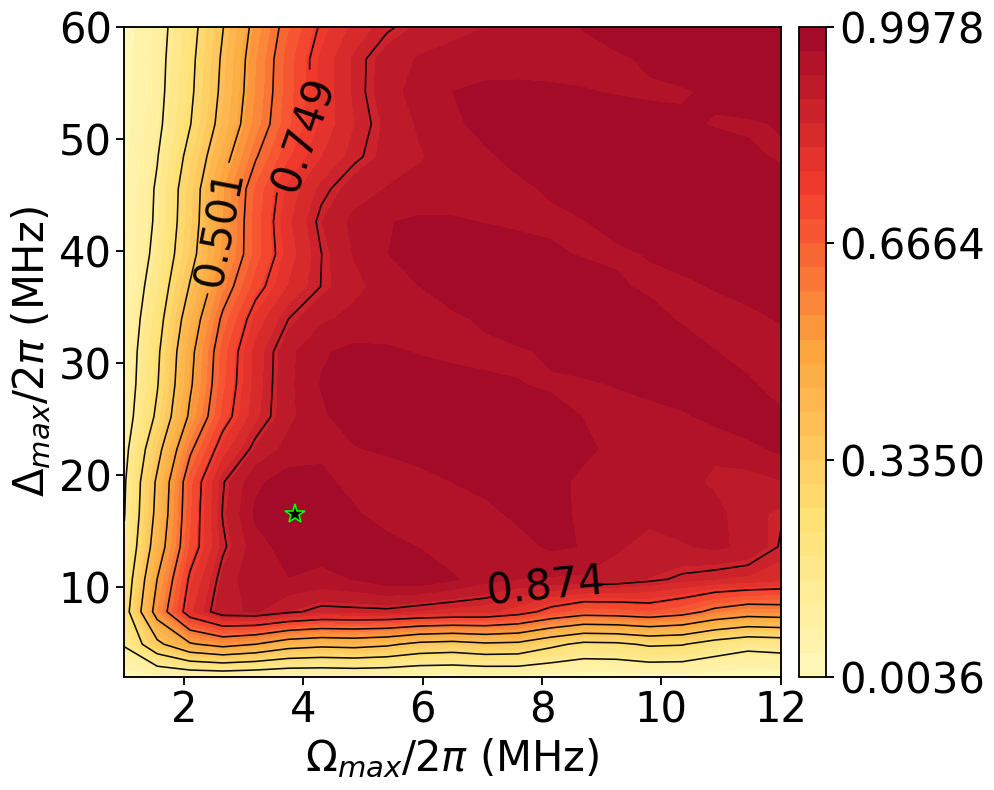

{
  "system": "3-qubit W state with dissipation",
  "constraint": "nominal Omega_max/(2*pi) < 5 MHz",
  "scan": {
    "grid_points": 21,
    "propagation_steps": 120
  },
  "LCF": {
    "parameters": [
      1012.1256479972835,
      134.5721346458133,
      453.3152082992042,
      0.16543188912172252,
      0.19881826786424547,
      0.0385313033102552,
      0.5404225914592502
    ],
    "Delta_max_MHz": 16.54318891217225,
    "V0_MHz": 19.881826786424547,
    "Omega_max_MHz": 3.85313033102552
  },
  "elapsed_s": 15.219768047332764
}


图片：C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\3bit_LCF_Delta_V.png


矢量图：C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\3bit_LCF_Delta_V.pdf


图片：C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\3bit_LCF_Omega_Delta.png


矢量图：C:\Users\13679\Documents\Codex\2026-10-13\ba-zh\outputs\3bit_LCF_Omega_Delta.pdf


In [12]:
%matplotlib inline
from IPython.display import display
import sys
sys.argv = ['已粘贴的文本.txt']
# -*- coding: utf-8 -*-

import json
import multiprocessing as mp
from multiprocessing.dummy import Pool as ThreadPool
import time
from itertools import product
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np


BASE = Path.cwd()


# ==================== 输出与快速扫描设置 ====================
OUT = BASE
WORK = BASE / "plot3_2x2_cache"
WORK.mkdir(parents=True, exist_ok=True)

M = 21                  # 每个方向的网格数；需要更快可改为 31 或 25
NSTEPS_GRID = 120       # 快速扫描传播步数
NSTEPS_METRIC = 400     # 标称点及 ±5% 噪声指标的传播步数
NPROC = min(4, mp.cpu_count())

# ==================== 单栏论文排版字体 ====================
# 图片原始宽度为 7.2 inch；在 LaTeX 中缩放到约 3.4 inch 单栏宽度后，
# 下列字号仍约等效为 7--10 pt。优先插入程序输出的矢量 PDF。
FS_TITLE = 30
FS_AXIS_LABEL = 30
FS_AXIS_TICK = 30
FS_CONTOUR = 30
FS_COLORBAR_LABEL = 30
FS_COLORBAR_TICK = 30

# 与参考图相同的加宽坐标范围。
DELTA_MHZ = np.linspace(2.0, 60.0, M)
V_MHZ = np.linspace(10.0, 120.0, M)
OMEGA_MHZ = np.linspace(1.0, 12.0, M)


# ==================== 3 比特各自最优参数 ====================
# 顺序：[tau, width_R, width_D, Delta0, V0, Omega_max, pulse_fraction]
# Omega_max 均满足 Omega_max/(2*pi) < 5 MHz。
P_LCF = np.array([
    1012.1256479972835,
    134.5721346458133,
    453.3152082992042,
    0.16543188912172252,
    0.19881826786424547,
    0.0385313033102552,
    0.5404225914592502,
])

P_RAP = np.array([
    757.2787453470203,
    126.46719759907164,
    478.6641811840292,
    0.03788497975165578,
    0.3102435427516243,
    0.03866829553191701,
    0.5,
])


# ==================== 完整的 3 比特含耗散模型 ====================
# 程序所需的物理模型与 fidelity 函数全部写在本文件中，不依赖其他源码。
OMEGA10 = 2.0 * np.pi * 100.0
GAMMA = (1.0 / 540.0) / OMEGA10
GAMMA_SPONT = GAMMA / 16.0
GAMMA_DEPH = 7.0 * GAMMA / 8.0

NATOM = 3
STATES = ["".join(state) for state in product("01r", repeat=NATOM)]
IDX = {state: i for i, state in enumerate(STATES)}
DIM = len(STATES)

# 三个原子的 1 <-> r 耦合矩阵；单原子矩阵元为 Omega/2。
COUPLING = np.zeros((DIM, DIM), dtype=complex)
for state, i in IDX.items():
    for atom in range(NATOM):
        if state[atom] == "1":
            target = state[:atom] + "r" + state[atom + 1:]
        elif state[atom] == "r":
            target = state[:atom] + "1" + state[atom + 1:]
        else:
            continue
        COUPLING[IDX[target], i] = 0.5

N_RYDBERG = np.array([state.count("r") for state in STATES], dtype=float)
N_RYDBERG_PAIRS = N_RYDBERG * (N_RYDBERG - 1.0) / 2.0
DIAG_INDEX = np.arange(DIM)

# 脉冲中点处施加 0 <-> 1 全局翻转。
GLOBAL_SWAP = np.array([
    IDX[state.replace("0", "_").replace("1", "0").replace("_", "1")]
    for state in STATES
])

PSI_INITIAL = np.zeros(DIM, dtype=complex)
PSI_INITIAL[IDX["111"]] = 1.0

PSI_TARGET = np.zeros(DIM, dtype=complex)
for atom in range(NATOM):
    state = ["0"] * NATOM
    state[atom] = "1"
    PSI_TARGET[IDX["".join(state)]] = 1.0 / np.sqrt(NATOM)

# 自发辐射跳跃通道 r -> 0、r -> 1。
SPONTANEOUS_CHANNELS = []
for atom in range(NATOM):
    for final_level in "01":
        source = np.array([
            i for state, i in IDX.items() if state[atom] == "r"
        ])
        destination = np.array([
            IDX[state[:atom] + final_level + state[atom + 1:]]
            for state, i in IDX.items() if state[atom] == "r"
        ])
        SPONTANEOUS_CHANNELS.append((source, destination))

# 纯退相干 Lindblad 项及反对易项。
DEPHASING_JUMP = np.zeros((DIM, DIM), dtype=float)
for atom in range(NATOM):
    mask = np.array([
        1.0 if state[atom] == "r" else 0.0 for state in STATES
    ])
    DEPHASING_JUMP += np.outer(mask, mask)
DEPHASING_JUMP *= GAMMA_DEPH
ANTICOMMUTATOR = GAMMA * (
    N_RYDBERG[:, None] + N_RYDBERG[None, :]
)


def pulse_arrays(kind, p, nstep):
    """生成 LCF 或 RAP 的 Omega(t)、Delta(t) 和时间步长。"""
    tau, width_r, width_d, delta0, v0, omega0, pulse_fraction = p
    t = (np.arange(nstep) + 0.5) * tau / nstep

    if kind == "lcf":
        t_pi = pulse_fraction * tau
        midpoint = np.where(
            t < t_pi,
            t_pi / 2.0,
            t_pi + (tau - t_pi) / 2.0,
        )
        x_r = (t - midpoint) / width_r
        x_d = (t - midpoint) / width_d
        omega = -omega0 * np.sqrt(2.0 * np.e) * x_r * np.exp(-x_r**2)
        delta = delta0 * np.e * x_d**2 * np.exp(-x_d**2)
        swap_step = int(round(pulse_fraction * nstep))
    elif kind == "rap":
        edge = np.exp(-((tau / (4.0 * width_r)) ** 4))
        half = np.where(t <= tau / 2.0, 1.0, 2.0)
        midpoint = (2.0 * half - 1.0) * tau / 4.0
        sign = np.where(half == 1.0, 1.0, -1.0)
        denominator = max(1.0 - edge, 1e-10)
        omega = omega0 * (
            np.exp(-((t - midpoint) / width_r) ** 4) - edge
        ) / denominator
        delta = delta0 * sign * np.sin(np.pi * (t - midpoint) / width_d)
        swap_step = nstep // 2
    else:
        raise ValueError("kind 必须是 'lcf' 或 'rap'")

    return omega, delta, v0, tau / nstep, swap_step


def fidelity(
    kind,
    p,
    omega_scale=1.0,
    delta_scale=1.0,
    v_scale=1.0,
    nstep=180,
    dissipation=True,
):
    """用完整 27 维 Lindblad 主方程计算 3 比特 W 态保真度。"""
    omega, delta, v0, dt, swap_step = pulse_arrays(kind, p, nstep)

    hamiltonian = (
        omega * omega_scale
    )[:, None, None] * COUPLING[None, :, :]
    hamiltonian[:, DIAG_INDEX, DIAG_INDEX] += (
        (delta * delta_scale)[:, None] * N_RYDBERG[None, :]
        + (v0 * v_scale) * N_RYDBERG_PAIRS[None, :]
    )

    eigenvalues, eigenvectors = np.linalg.eigh(hamiltonian)
    half_step = (
        eigenvectors
        * np.exp(-1j * eigenvalues * dt / 2.0)[:, None, :]
    ) @ np.swapaxes(eigenvectors.conj(), 1, 2)

    rho = np.outer(PSI_INITIAL, PSI_INITIAL.conj())
    for step in range(nstep):
        propagator = half_step[step]
        rho = propagator @ rho @ propagator.conj().T

        if dissipation:
            jump = DEPHASING_JUMP * rho
            for source, destination in SPONTANEOUS_CHANNELS:
                jump[np.ix_(destination, destination)] += (
                    GAMMA_SPONT * rho[np.ix_(source, source)]
                )
            rho += dt * (jump - 0.5 * ANTICOMMUTATOR * rho)

        rho = propagator @ rho @ propagator.conj().T

        if step == swap_step - 1:
            rho = rho[np.ix_(GLOBAL_SWAP, GLOBAL_SWAP)]

    return float(np.real(PSI_TARGET.conj() @ rho @ PSI_TARGET))


def calc_one(args):
    """计算一个绝对参数点的保真度。"""
    kind, p, omega_mhz, delta_mhz, v_mhz = args
    return fidelity(
        kind,
        p,
        omega_mhz / (100.0 * p[5]),
        delta_mhz / (100.0 * p[3]),
        v_mhz / (100.0 * p[4]),
        nstep=NSTEPS_GRID,
    )


def panel_grid(kind, p, mode, pool):
    """生成一个面板的快速扫描网格。"""
    if mode == "DV":
        # 固定本方案自己的最优 Omega_max，扫描 (Delta_max, V0)。
        tasks = [
            (kind, p, 100.0 * p[5], delta, v0)
            for v0 in V_MHZ
            for delta in DELTA_MHZ
        ]
        shape = (len(V_MHZ), len(DELTA_MHZ))
    elif mode == "OD":
        # 固定本方案自己的最优 V0，扫描 (Omega_max, Delta_max)。
        tasks = [
            (kind, p, omega, delta, 100.0 * p[4])
            for delta in DELTA_MHZ
            for omega in OMEGA_MHZ
        ]
        shape = (len(DELTA_MHZ), len(OMEGA_MHZ))
    else:
        raise ValueError("mode 必须是 'DV' 或 'OD'")

    values = list(pool.imap(calc_one, tasks, chunksize=8))
    return np.asarray(values).reshape(shape)


def robust_metrics(kind, p):
    """中心保真度和 Omega_max、Delta_max 同时 ±5% 下的最坏保真度。"""
    noise_values = [
        fidelity(kind, p, 1.0 + d_omega, 1.0 + d_delta,
                 nstep=NSTEPS_METRIC)
        for d_omega in (-0.05, 0.0, 0.05)
        for d_delta in (-0.05, 0.0, 0.05)
    ]
    return {
        "F0": float(fidelity(kind, p, nstep=NSTEPS_METRIC)),
        "worst5": float(min(noise_values)),
        "mean5": float(np.mean(noise_values)),
    }


def fidelity_panel(
    ax, x, y, grid, title, optimum, cmap, label_positions,
    line_indices=None,
):
    """绘制独立颜色范围、平头色标的单张保真度等高图。"""
    f_min = float(np.nanmin(grid))
    f_max = float(np.nanmax(grid))
    if np.isclose(f_min, f_max):
        pad = max(abs(f_min) * 1e-6, 1e-9)
        f_min, f_max = f_min - pad, f_max + pad

    fill_levels = np.linspace(f_min, f_max, 28)
    # 恢复接近原六图版的等高线密度，但只给隔一条线标注数值。
    all_line_levels = np.linspace(f_min, f_max, 9)[1:-1]
    if line_indices is None:
        line_levels = all_line_levels
    else:
        line_levels = all_line_levels[np.asarray(line_indices, dtype=int)]

    # 不设置 extend，因此颜色标尺两端为平头。
    cf = ax.contourf(x, y, grid, levels=fill_levels, cmap=cmap)
    cs = ax.contour(
        x, y, grid, levels=line_levels,
        colors="black", linewidths=1.15, alpha=0.95,
    )
    ax.clabel(
        cs, fmt="%.3f", fontsize=FS_CONTOUR,
        inline=True, inline_spacing=4, manual=label_positions,
    )
    ax.plot(
        optimum[0], optimum[1], "*", ms=15,
        color="black", markeredgecolor="lime", markeredgewidth=1.2,
    )
    # 论文版不在子图上方显示标题；方案与参数信息放在正文或图注中。
    ax.tick_params(
        axis="both", labelsize=FS_AXIS_TICK,
        width=1.35, length=5.5,
    )
    for spine in ax.spines.values():
        spine.set_linewidth(1.35)
    return cf


def main():
    start = time.time()
    cache_path = WORK / f"lcf_two_panels_M{M}_steps{NSTEPS_GRID}.npz"

    if cache_path.exists():
        cache = np.load(cache_path)
        lcf_dv = cache["lcf_DV"]
        lcf_od = cache["lcf_OD"]
        print("已读取 LCF 两面板缓存。", flush=True)
    else:
        with ThreadPool(processes=NPROC) as pool:
            print("扫描 LCF 的 (Delta_max, V0)...", flush=True)
            lcf_dv = panel_grid("lcf", P_LCF, "DV", pool)

            print("扫描 LCF 的 (Omega_max, Delta_max)...", flush=True)
            lcf_od = panel_grid("lcf", P_LCF, "OD", pool)

        np.savez_compressed(
            cache_path,
            delta_mhz=DELTA_MHZ,
            v_mhz=V_MHZ,
            omega_mhz=OMEGA_MHZ,
            lcf_DV=lcf_dv,
            lcf_OD=lcf_od,
            params_lcf=P_LCF,
        )

    delta_lcf, v_lcf, omega_lcf = 100.0 * P_LCF[3:6]

    cmap_ref = LinearSegmentedColormap.from_list("ref_yor", [
        (1.000, 0.976, 0.737),
        (1.000, 0.878, 0.451),
        (0.992, 0.651, 0.247),
        (0.953, 0.231, 0.176),
        (0.624, 0.031, 0.157),
    ])

    def save_one(name, x, y, grid, optimum, xlabel, ylabel,
                 xlim, ylim, xticks, yticks, label_positions,
                 line_indices=None):
        """将一个面板保存为独立 PNG 和独立矢量 PDF。"""
        fig, ax = plt.subplots(figsize=(10, 8))
        cf = fidelity_panel(
            ax, x, y, grid, "", optimum, cmap_ref, label_positions,
            line_indices=line_indices,
        )
        ax.set_xlim(*xlim)
        ax.set_ylim(*ylim)
        ax.set_xticks(xticks)
        ax.set_yticks(yticks)
        ax.set_xlabel(xlabel, fontsize=FS_AXIS_LABEL)
        ax.set_ylabel(ylabel, fontsize=FS_AXIS_LABEL)

        zlo, zhi = cf.get_clim()
        cbar = fig.colorbar(
            cf, ax=ax, ticks=np.linspace(zlo, zhi, 4),
            pad=0.025, fraction=0.055, aspect=24,
        )
        cbar.ax.tick_params(
            labelsize=FS_COLORBAR_TICK, width=1.4, length=6
        )
        cbar.ax.yaxis.set_major_formatter(
            matplotlib.ticker.FormatStrFormatter("%.4f")
        )
        cbar.outline.set_linewidth(1.3)

        fig.tight_layout()
        png = OUT / f"{name}.png"
        pdf = OUT / f"{name}.pdf"
        fig.savefig(png, dpi=200)
        fig.savefig(pdf)
        display(fig)
        plt.close(fig)
        return png, pdf

    outputs = []
    outputs.append(save_one(
        "3bit_LCF_Delta_V", DELTA_MHZ, V_MHZ, lcf_dv,
        (delta_lcf, v_lcf),
        r"$\Delta_{max}/2\pi$ (MHz)", r"$V_0/2\pi$ (MHz)",
        (2.0, 60.0), (10.0, 120.0),
        np.arange(10.0, 61.0, 10.0), np.arange(20.0, 121.0, 20.0),
        [(6.0, 105.0), (8.0, 86.0), (36.0, 70.0)],
        line_indices=[4, 6],
    ))
    outputs.append(save_one(
        "3bit_LCF_Omega_Delta", OMEGA_MHZ, DELTA_MHZ, lcf_od,
        (omega_lcf, delta_lcf),
        r"$\Omega_{max}/2\pi$ (MHz)", r"$\Delta_{max}/2\pi$ (MHz)",
        (1.0, 12.0), (2.0, 60.0),
        np.arange(2.0, 12.1, 2.0), np.arange(10.0, 60.1, 10.0),
        [(2.6, 42.0), (4.1, 50.0), (8.0, 13.0)],
    ))
    data_path = OUT / "3bit_LCF_two_panels_grids.npz"
    report_path = OUT / "3bit_LCF_two_panels_parameters.json"

    np.savez_compressed(
        data_path,
        delta_mhz=DELTA_MHZ,
        v_mhz=V_MHZ,
        omega_mhz=OMEGA_MHZ,
        lcf_DV=lcf_dv,
        lcf_OD=lcf_od,
        params_lcf=P_LCF,
    )

    report = {
        "system": "3-qubit W state with dissipation",
        "constraint": "nominal Omega_max/(2*pi) < 5 MHz",
        "scan": {"grid_points": M, "propagation_steps": NSTEPS_GRID},
        "LCF": {
            "parameters": P_LCF.tolist(),
            "Delta_max_MHz": delta_lcf,
            "V0_MHz": v_lcf,
            "Omega_max_MHz": omega_lcf,
        },
        "elapsed_s": time.time() - start,
    }
    report_path.write_text(
        json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(json.dumps(report, ensure_ascii=False, indent=2), flush=True)
    for png_path, pdf_path in outputs:
        print(f"图片：{png_path}", flush=True)
        print(f"矢量图：{pdf_path}", flush=True)


if __name__ == "__main__":
    mp.freeze_support()
    main()
